## **LAB 2: Learning regression and classification models with electronic health records**

Àlex Font Bartumeus, 266147

Iris Azlor Solé, 266871


**Goal:**


*   Predict if a given patient will be readmitted
*   Estimate the expected length of stay for a given patient



### **1. Exploratory data analysis**

Use your findings to select the features
you are going to use and reason hypotheses about their potential relationships (look for features that introduce data leakage and remove them)


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
%pip install ucimlrepo
from ucimlrepo import fetch_ucirepo

Note: you may need to restart the kernel to use updated packages.


In [3]:
# We start by loading the data. We must notice that the dataset is provided as an Excel and that information is separated by a semicolon.

dataset = pd.read_csv('real_patients.csv', sep = ';')

print('Shape: ', dataset.shape)
display(dataset.head()) # we display the first 5 patients to see how does the dataset look like
display(dataset.describe(include='all')) #we include categorical variables also

Shape:  (25000, 17)


,age,time_in_hospital,n_lab_procedures,n_procedures,n_medications,n_outpatient,n_inpatient,n_emergency,medical_specialty,diag_1,diag_2,diag_3,glucose_test,A1Ctest,change,diabetes_med,readmitted
0,[70-80),8,72,1,18,2,0,0,Missing,Circulatory,Respiratory,Other,no,no,no,yes,no
1,[70-80),3,34,2,13,0,0,0,Other,Other,Other,Other,no,no,no,yes,no
2,[50-60),5,45,0,18,0,0,0,Missing,Circulatory,Circulatory,Circulatory,no,no,yes,yes,yes
3,[70-80),2,36,0,12,1,0,0,Missing,Circulatory,Other,Diabetes,no,no,yes,yes,yes
4,[60-70),1,42,0,7,0,0,0,InternalMedicine,Other,Circulatory,Respiratory,no,no,no,yes,no


,age,time_in_hospital,n_lab_procedures,n_procedures,n_medications,n_outpatient,n_inpatient,n_emergency,medical_specialty,diag_1,diag_2,diag_3,glucose_test,A1Ctest,change,diabetes_med,readmitted
count,25000,25000.00000,25000.00000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000,25000,25000,25000,25000,25000,25000,25000,25000
unique,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7,8,8,8,3,3,2,2,2
top,[70-80),NaN,NaN,NaN,NaN,NaN,NaN,NaN,Missing,Circulatory,Other,Other,no,no,no,yes,no
freq,6837,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12382,7824,9056,9107,23625,20938,13497,19228,13246
mean,NaN,4.45332,43.24076,1.352360,16.252400,0.366400,0.615960,0.186600,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,3.00147,19.81862,1.715179,8.060532,1.195478,1.177951,0.885873,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,1.00000,1.00000,0.000000,1.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,2.00000,31.00000,0.000000,11.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,4.00000,44.00000,1.000000,15.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,6.00000,57.00000,2.000000,20.000000,0.000000,1.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# Print the columns, types and missing values in the dataset
print("Columns:")
print(dataset.columns.tolist())

print("\nTypes:")
display(dataset.dtypes)

print("\nMissing values in each column:")
display(dataset.isnull().sum().sort_values(ascending=False))

Columns:
['age', 'time_in_hospital', 'n_lab_procedures', 'n_procedures', 'n_medications', 'n_outpatient', 'n_inpatient', 'n_emergency', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'glucose_test', 'A1Ctest', 'change', 'diabetes_med', 'readmitted']

Types:


age                    str
time_in_hospital     int64
n_lab_procedures     int64
n_procedures         int64
n_medications        int64
n_outpatient         int64
n_inpatient          int64
n_emergency          int64
medical_specialty      str
diag_1                 str
diag_2                 str
diag_3                 str
glucose_test           str
A1Ctest                str
change                 str
diabetes_med           str
readmitted             str
dtype: object


Missing values in each column:


age                  0
time_in_hospital     0
n_lab_procedures     0
n_procedures         0
n_medications        0
n_outpatient         0
n_inpatient          0
n_emergency          0
medical_specialty    0
diag_1               0
diag_2               0
diag_3               0
glucose_test         0
A1Ctest              0
change               0
diabetes_med         0
readmitted           0
dtype: int64

We have checked the columns in this cell that we have in the dataset and we have seen that we have categorical (object) and numeric (int64) variables. Moreover, we have confirmed if there exists Nan values.

Since our objective is to predict the readmission and the length of stay of a patient, we have to use the features: readmitted and time in hospital.

In [5]:
# Columns we want to predict (goals)
target_classification = 'readmitted' #yes/no values
target_regression = 'time_in_hospital' #numerical value

#As we did in class we define the continuous and count numerical features:
continuous_features = ['time_in_hospital']
count_features = ['n_lab_procedures', 'n_procedures', 'n_medications','n_outpatient', 'n_inpatient', 'n_emergency']

numerical_features= continuous_features + count_features

# Even though we use time in hospital as our target for regression, we include it
# for the analysis to see how does it distribute and relate with other variables

# We also define the categorical features (like nominal/binary/ordinal seen in class):
categorical_features = ['age', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3',
    'glucose_test', 'A1Ctest', 'change', 'diabetes_med']

#EXPLORATORY DATA ANALYSIS
input_features = count_features + categorical_features + ['time_in_hospital']
print('Numerical features: ', count_features)
print('Categorical features: ', categorical_features)



Numerical features:  ['n_lab_procedures', 'n_procedures', 'n_medications', 'n_outpatient', 'n_inpatient', 'n_emergency']
Categorical features:  ['age', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'glucose_test', 'A1Ctest', 'change', 'diabetes_med']


readmitted
no     13246
yes    11754
Name: count, dtype: int64
readmitted
no     0.52984
yes    0.47016
Name: proportion, dtype: float64


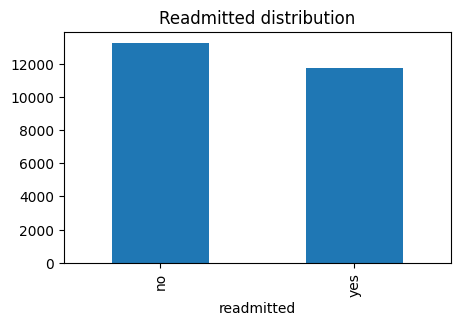

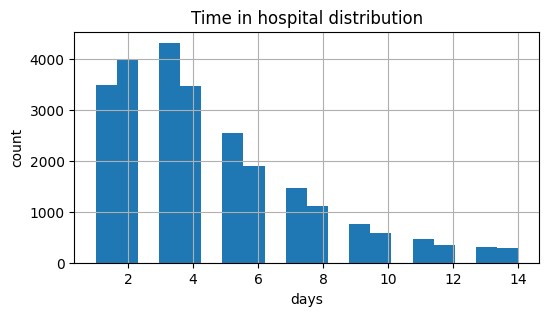

count    25000.00000
mean         4.45332
std          3.00147
min          1.00000
25%          2.00000
50%          4.00000
75%          6.00000
max         14.00000
Name: time_in_hospital, dtype: float64

In [6]:
# Now, we look for the distribution of the target variables, to have an overview. 

# Classification: readmitted
print(dataset[target_classification].value_counts())
print(dataset[target_classification].value_counts(normalize=True))

plt.figure(figsize=(5,3))
dataset[target_classification].value_counts().plot(kind='bar')
plt.title("Readmitted distribution")
plt.show()

# Regression: time_in_hospital
plt.figure(figsize=(6,3))
dataset[target_regression].hist(bins=20)
plt.title("Time in hospital distribution")
plt.xlabel("days")
plt.ylabel("count")
plt.show()

display(dataset[target_regression].describe())

With these plots, we can study whether the readmitted patient rate is unbalanced and what the distribution of length of stay is. As we can observe, 13,246 patients are not readmitted, and 11,754 patients are readmitted. These values ​​indicate that the classes are relatively balanced, and therefore, we can train classification models without having to use aggressive balancing techniques.
Regarding the distribution of time in the hospital, we see that the average stay is 4.45 days, and the standard deviation is approximately 3 days. Therefore, most stays fall within short ranges, and there are few cases of long stays. However, this dispersion in the values ​​indicates that there are clinical and patient history factors that affect the variability.

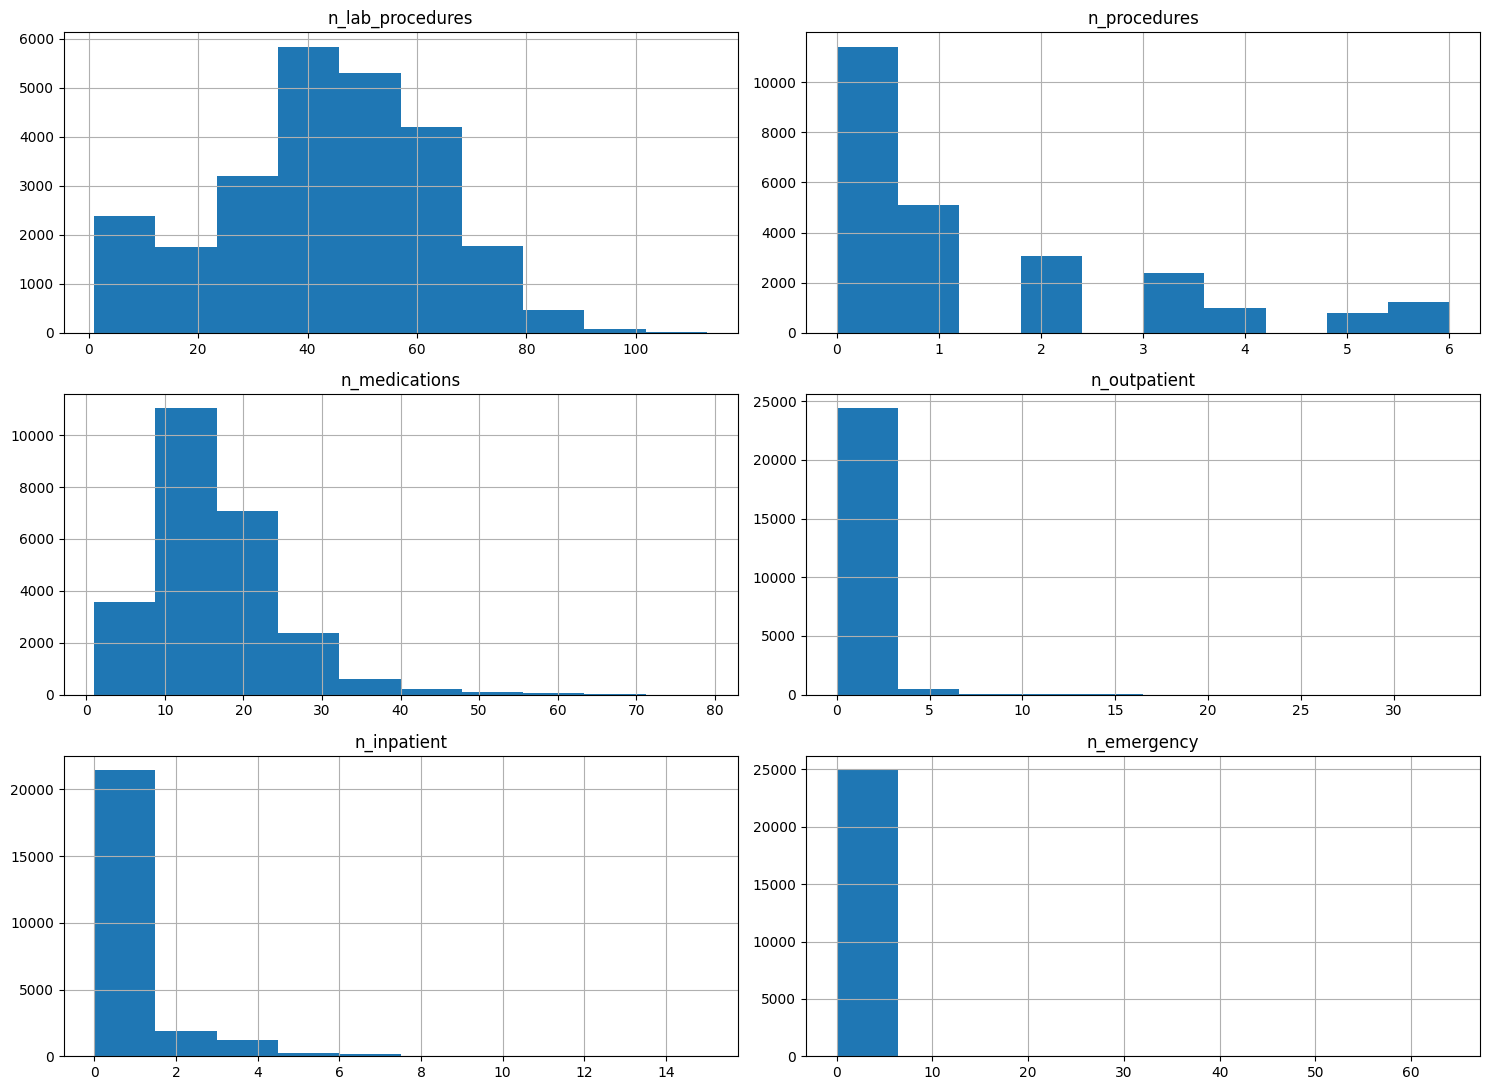

In [7]:
#We print the histogram for the numerical features

dataset[count_features].hist(figsize=(15,11))
plt.tight_layout()
plt.show()

When we look at the distribution of the numerical variables, we see that most histograms are skewed to the right. This means that many patients have low values. This skew is most noticeable in procedures, outpatient, inpatient, and emergency, with many zero values. In contrast, lab procedures and medications show greater dispersion, as well as some extreme cases.

These results suggest that further scaling and consideration of outliers will be necessary.

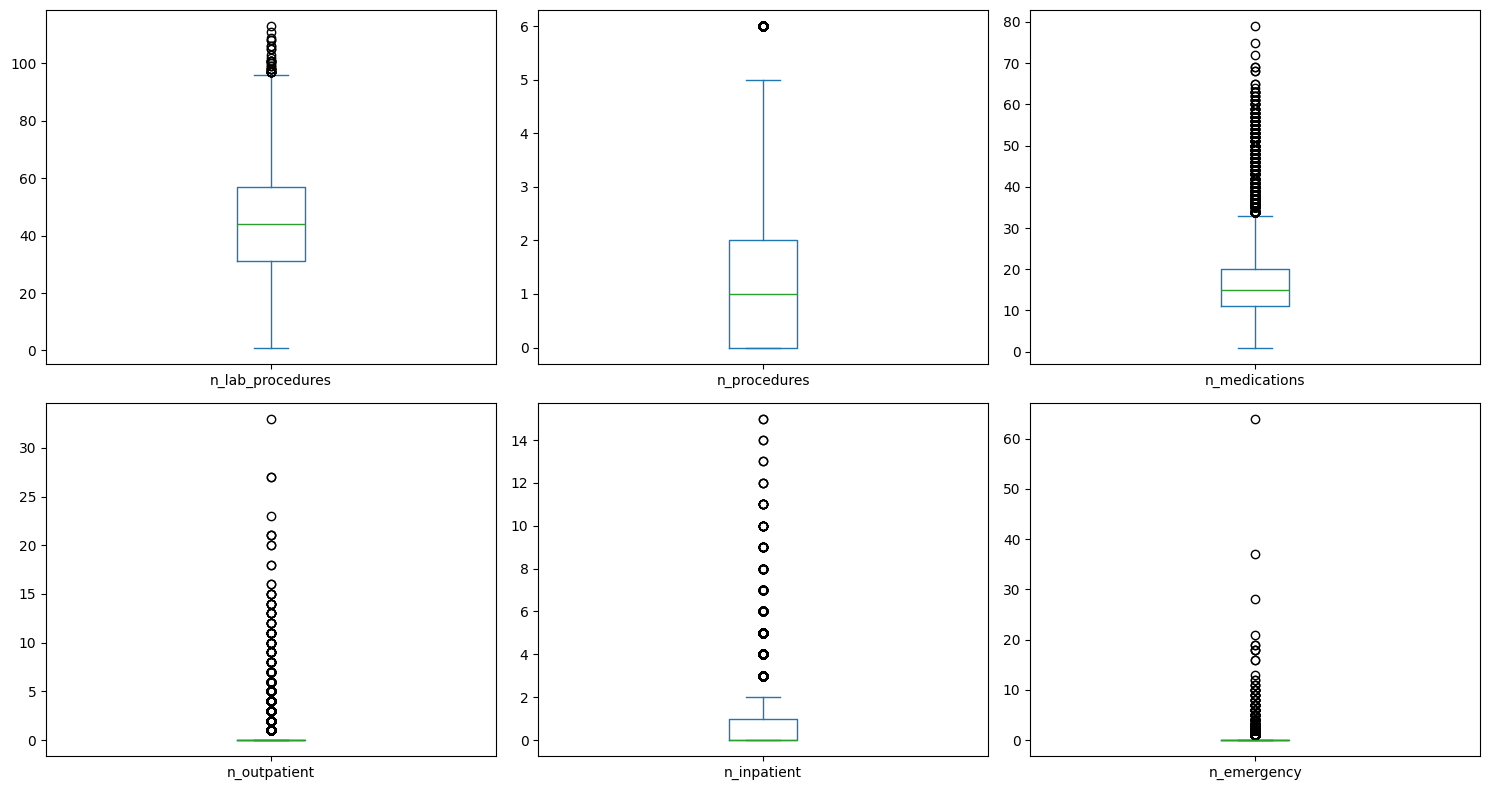

In [8]:
# We apply now the boxplots seen in class
dataset[count_features].plot(kind='box', subplots=True, layout=(2,3), figsize=(15, 8))
plt.tight_layout()
plt.show()

We can observe that the boxplots show many outliers across all variables, indicating that some patients have significantly higher values ​​than the majority. As we saw earlier, the median is close to 0 for outpatient, inpatient, and emergency departments.

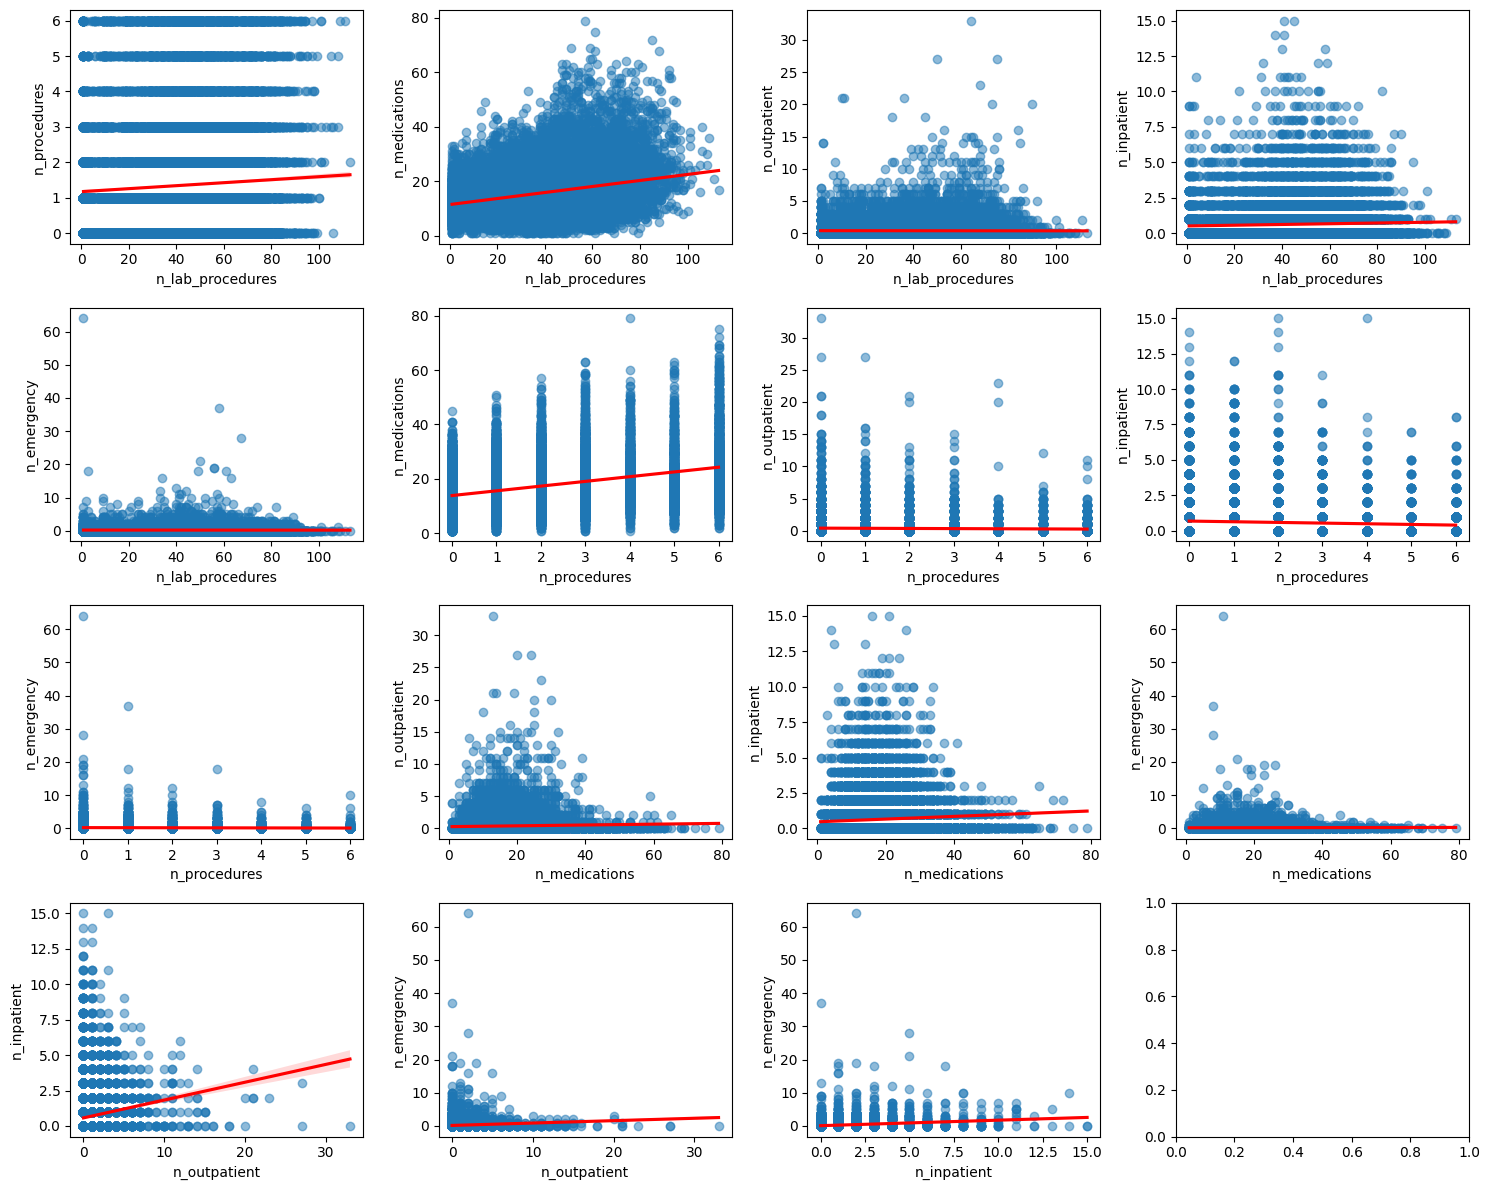

In [9]:
# We look for relationships between numerical features
pairs = []
for i in range(len(count_features)):
  for j in range(i + 1, len(count_features)):
    pairs.append((count_features[i], count_features[j]))
n_pairs = len(pairs)
ncols = 4
nrows=(n_pairs + ncols -1)// ncols

fig, axs = plt.subplots(nrows, ncols, figsize = (15,3*nrows))
axes_flat = axs.flatten()

for k, (feature_A, feature_B) in enumerate(pairs):
  ax = axes_flat[k]
  sns.regplot(
      x=dataset[feature_A],
      y = dataset[feature_B],
      ax = ax,
      scatter_kws = {'alpha': 0.5},
      line_kws = {'color':'red'}
  )


plt.tight_layout()
plt.show()

Looking at the relationships between the numerical variables, we see that most of the data points are concentrated in the low values, indicating significant dispersion. However, we can also observe some positive trends (the red line is rising) between lab procedures and medication, indicating that patients with more lab tests tend to have more medication; similarly, there is a positive trend between procedures and medications, suggesting that more procedures mean more medication.

The graphs also show that for features such as outpatient/inpatient/emergency, the relationship is very weak or nonexistent (horizontal line).

Overall, the numerical counting variables are not strongly related to each other; most are weak or nonexistent. Those that show positive trends are usually mild.

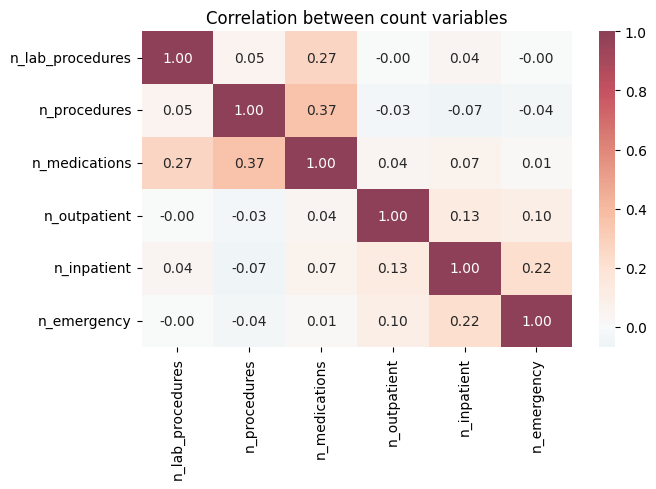

In [10]:
corr = dataset[count_features].corr()

plt.figure(figsize=(7,5))
sns.heatmap(
    corr,
    annot=True,  # to show the numbers of each varible      
    fmt=".2f",         
    center=0,
    cmap="RdBu_r",   
    alpha=0.75
)
plt.title("Correlation between count variables")
plt.tight_layout()
plt.show()
# Heatmap to visualize the results of the regplots

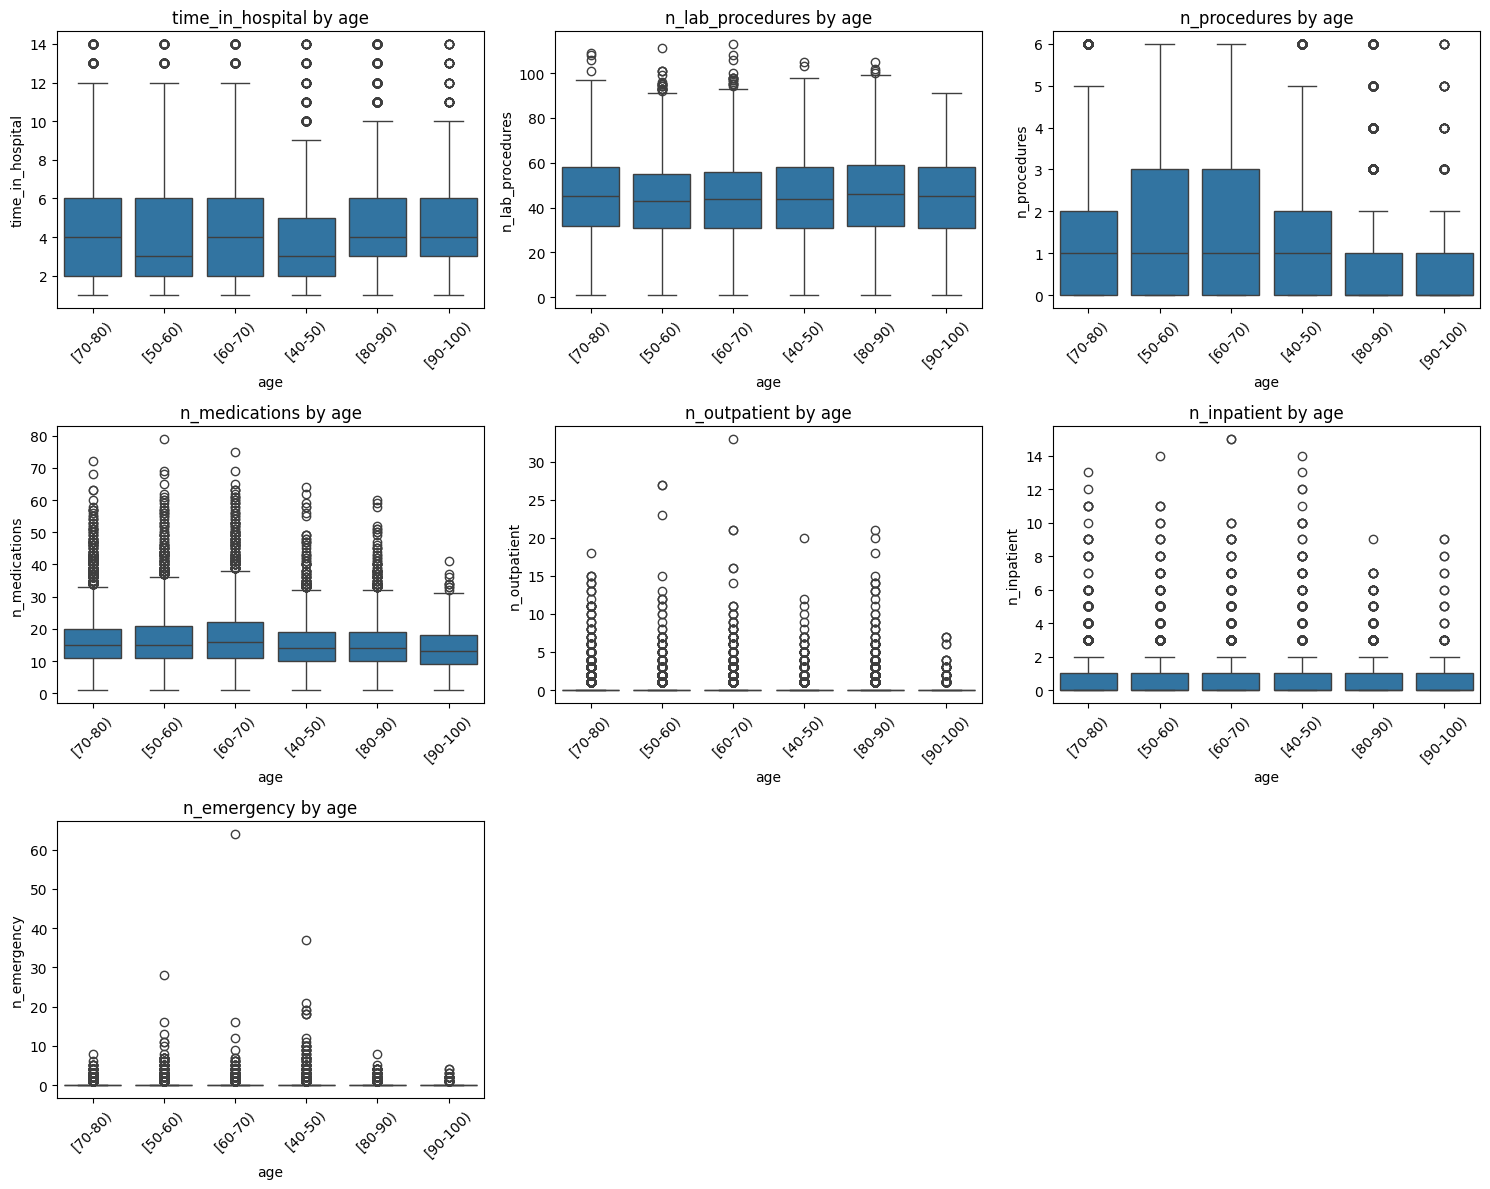

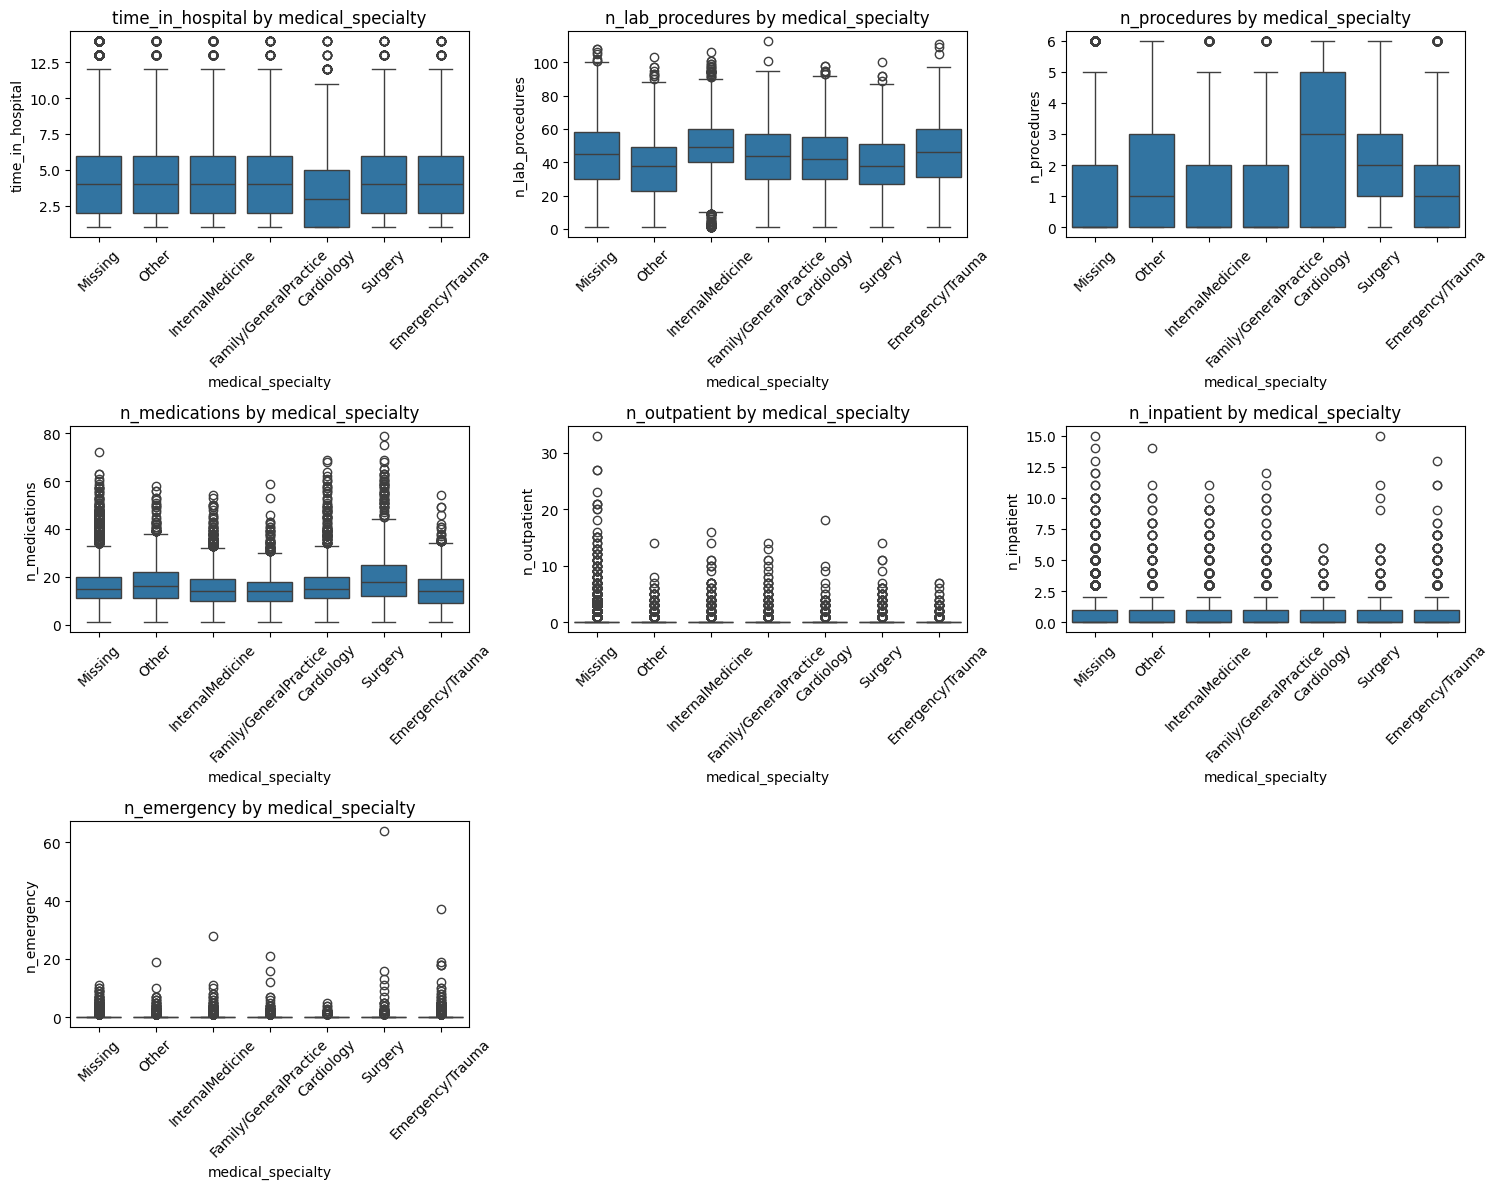

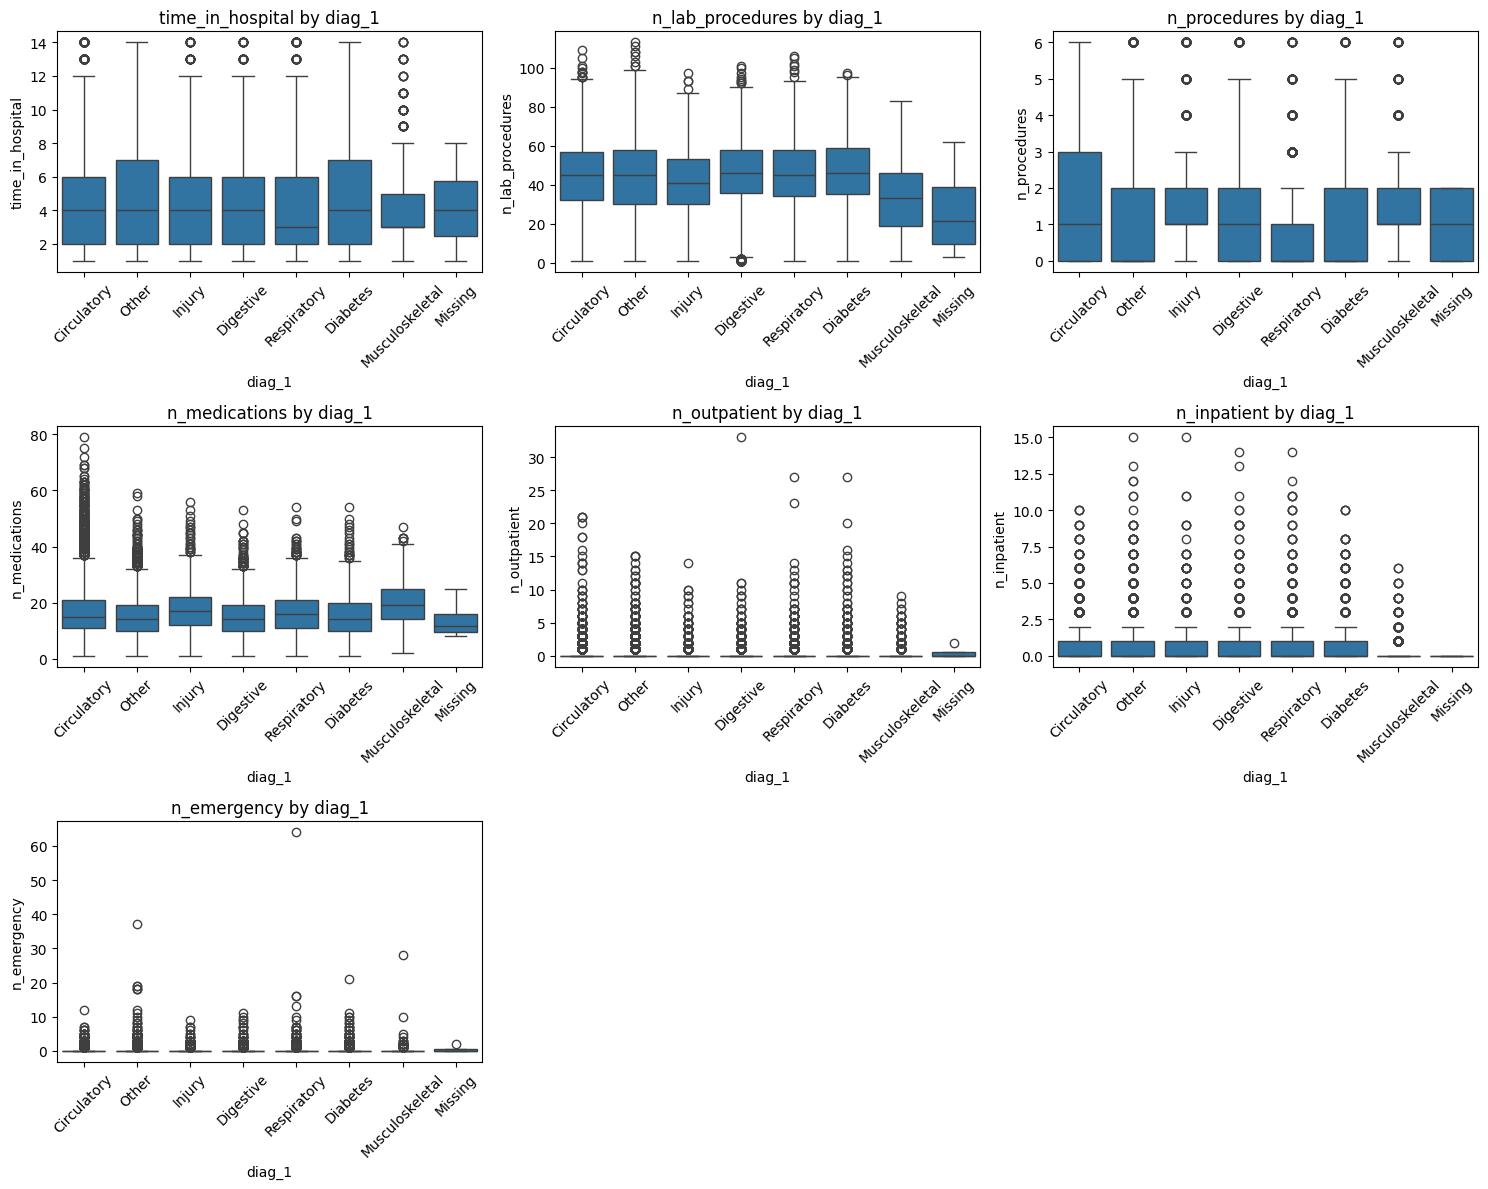

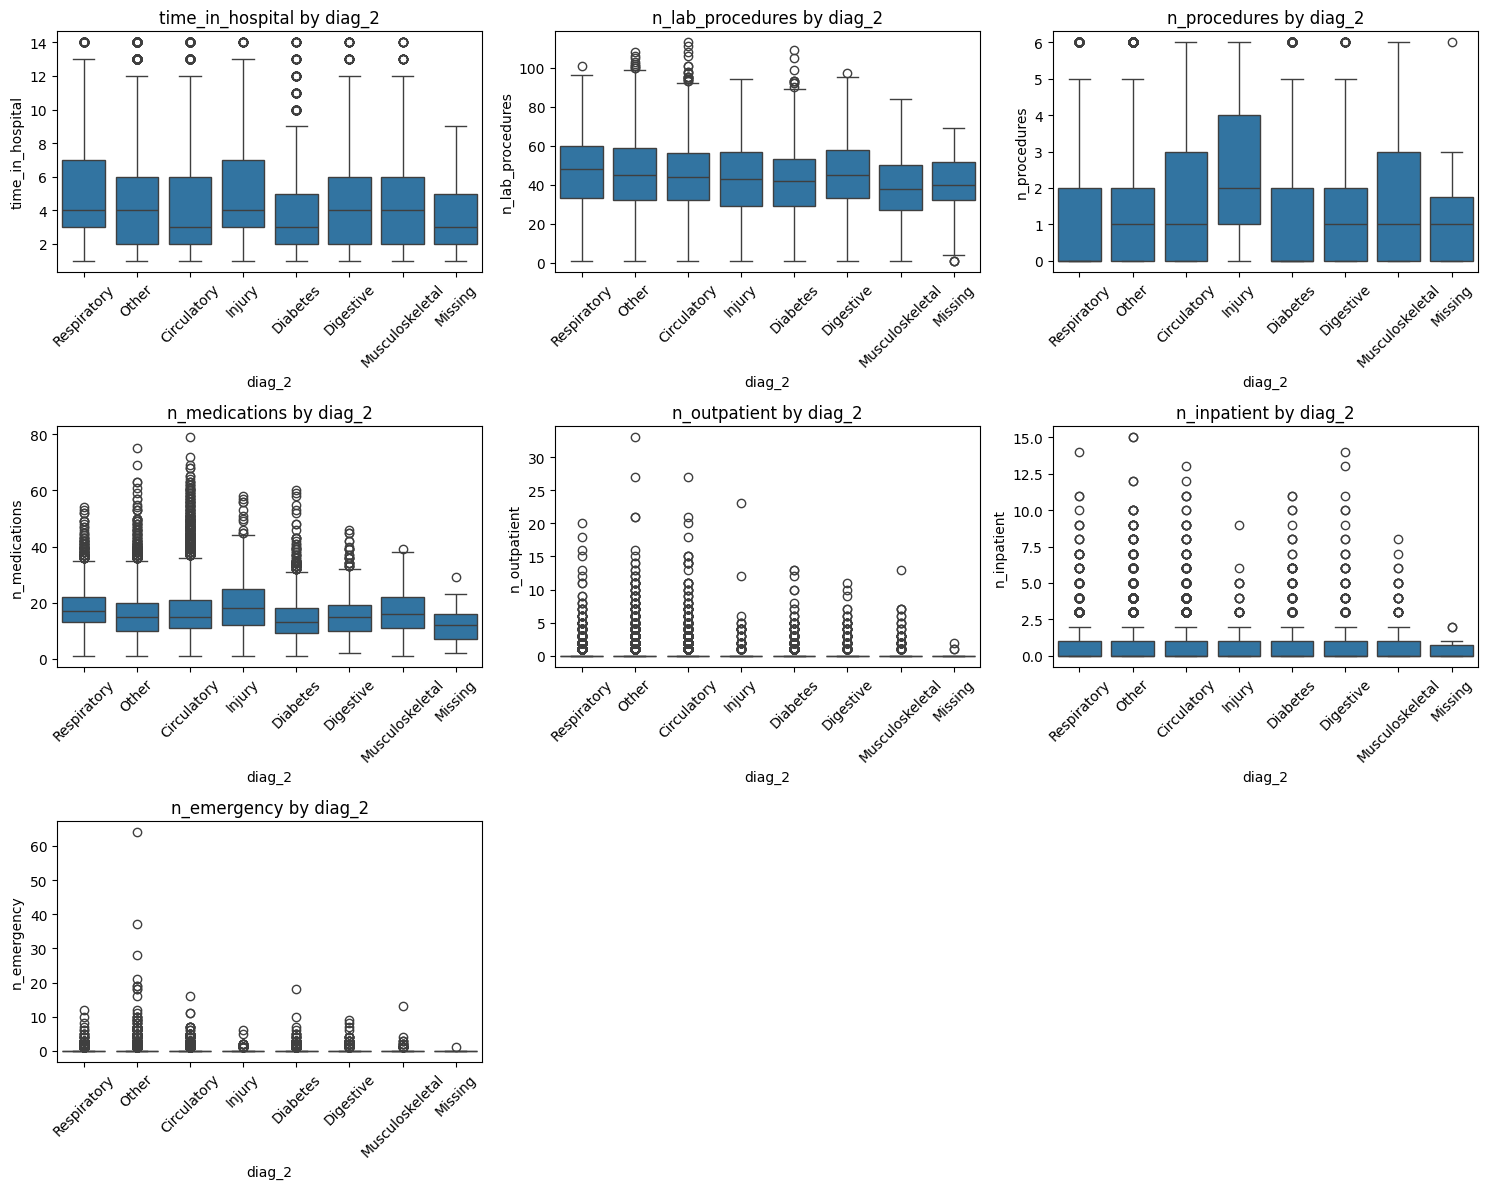

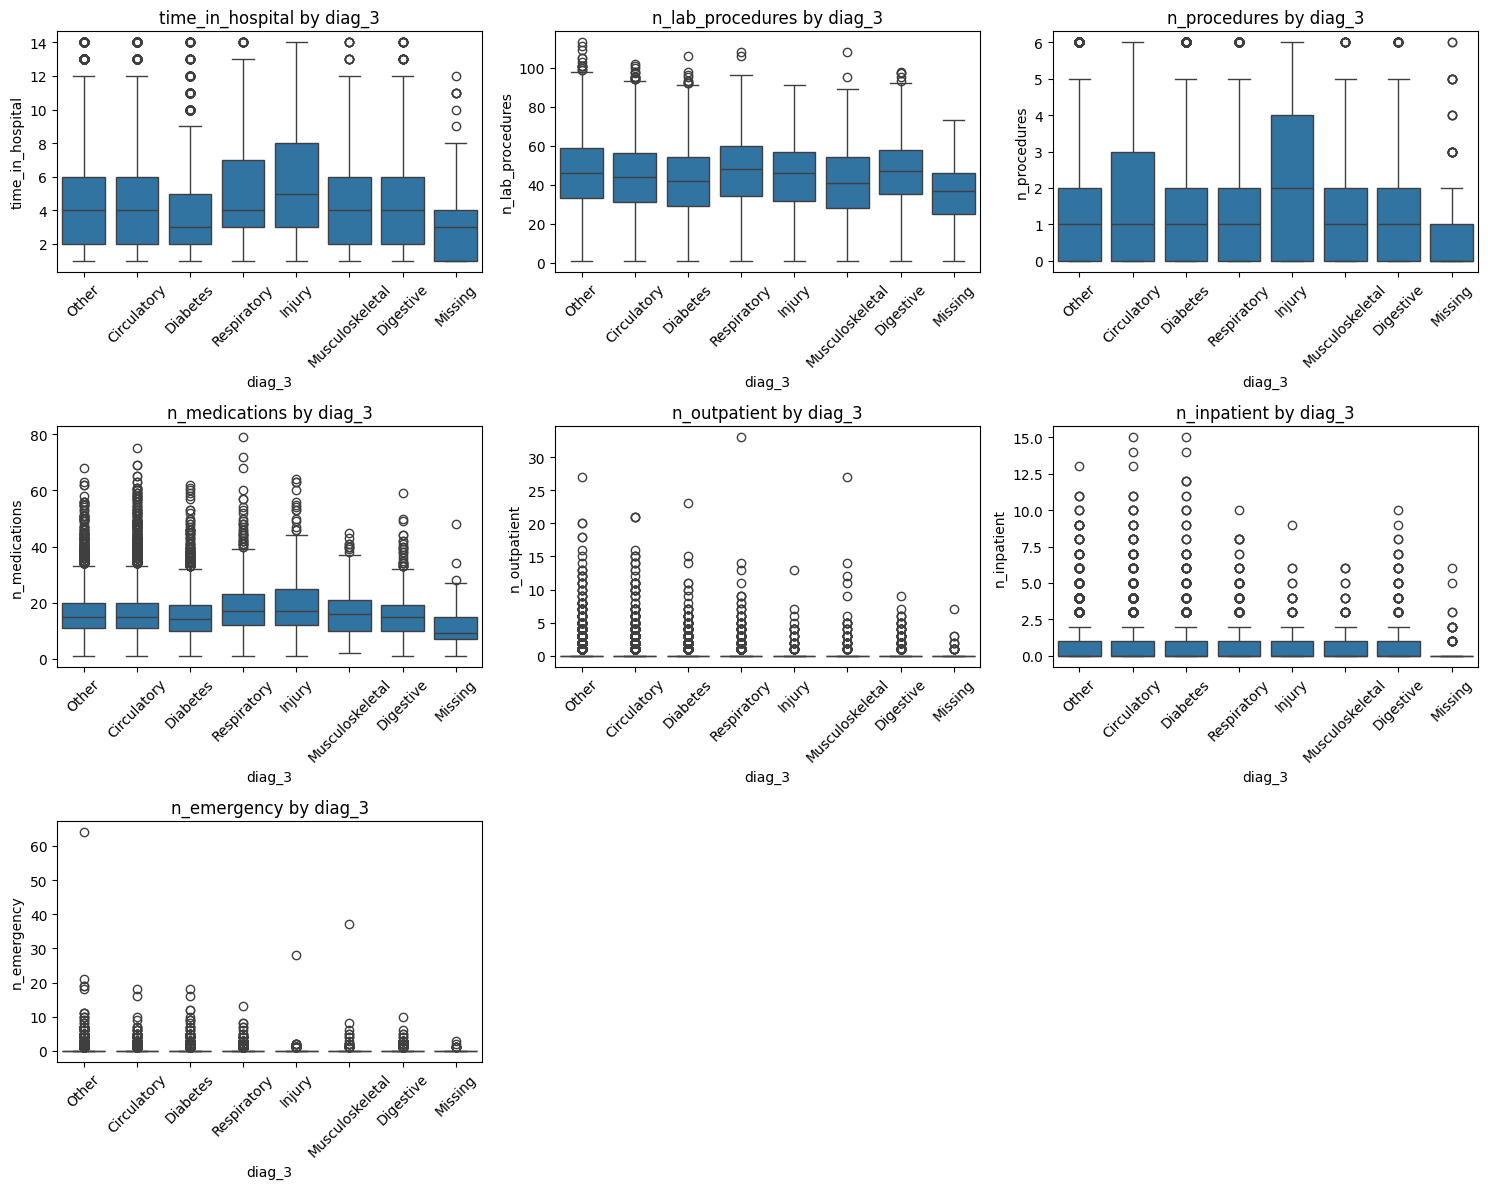

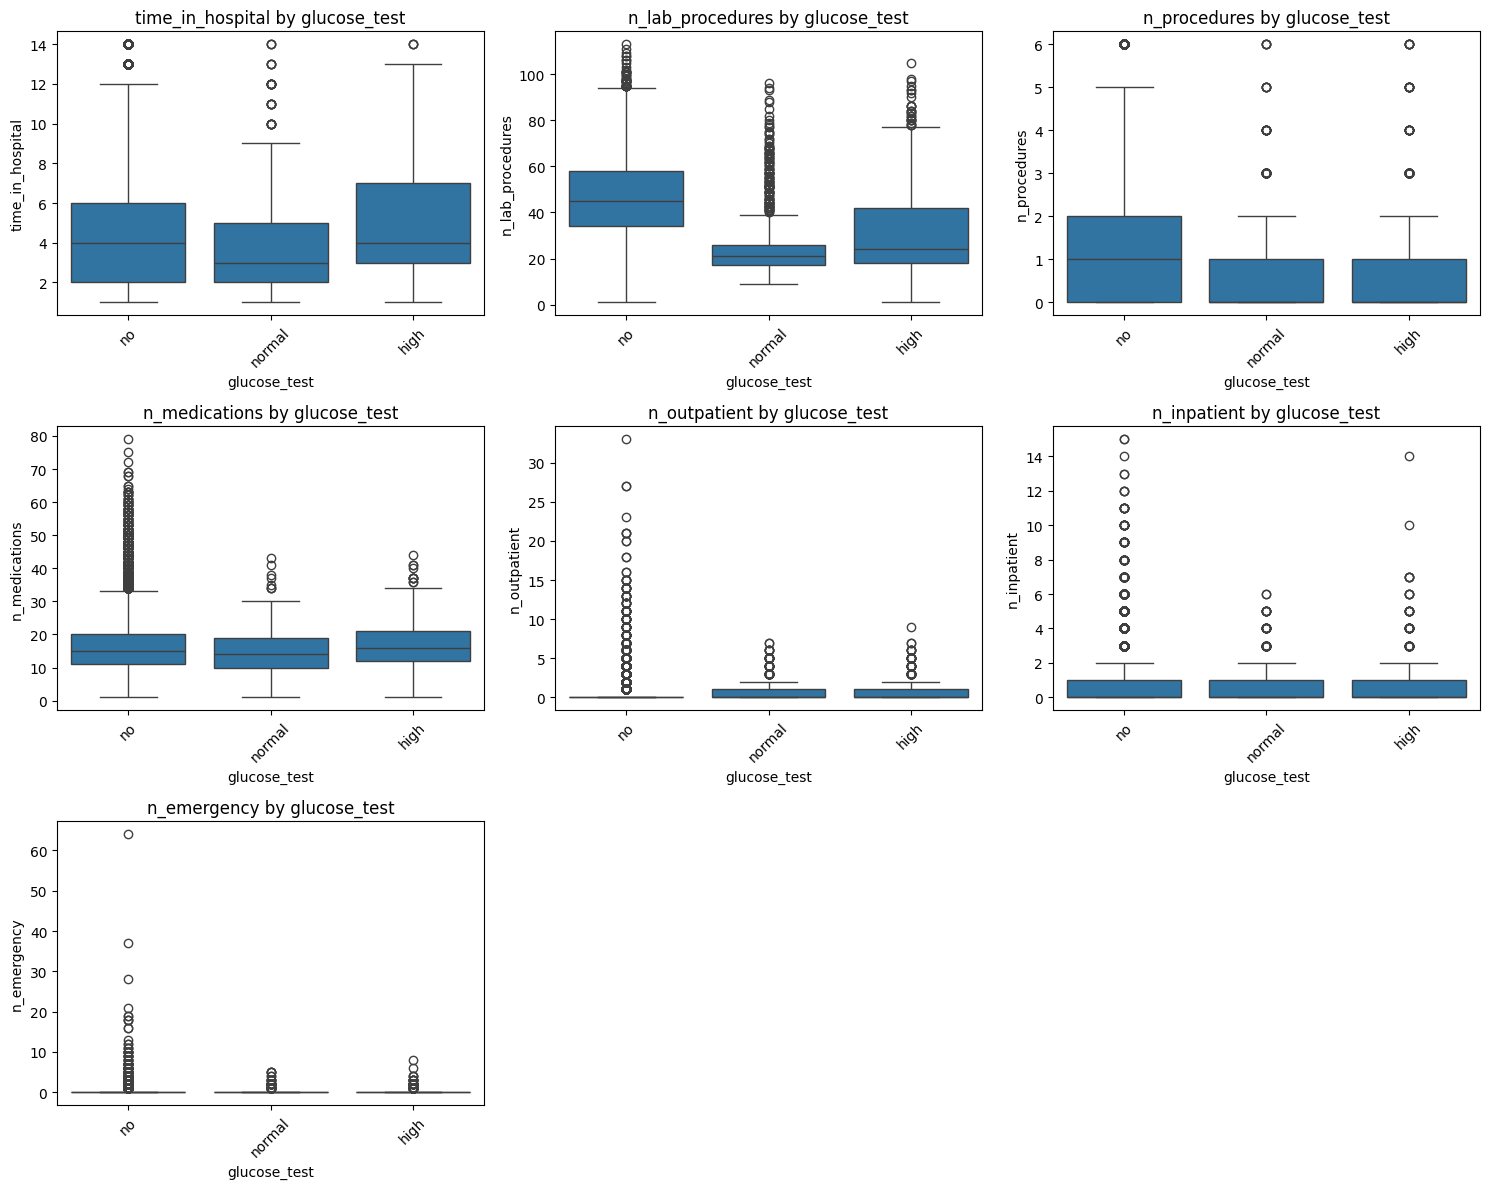

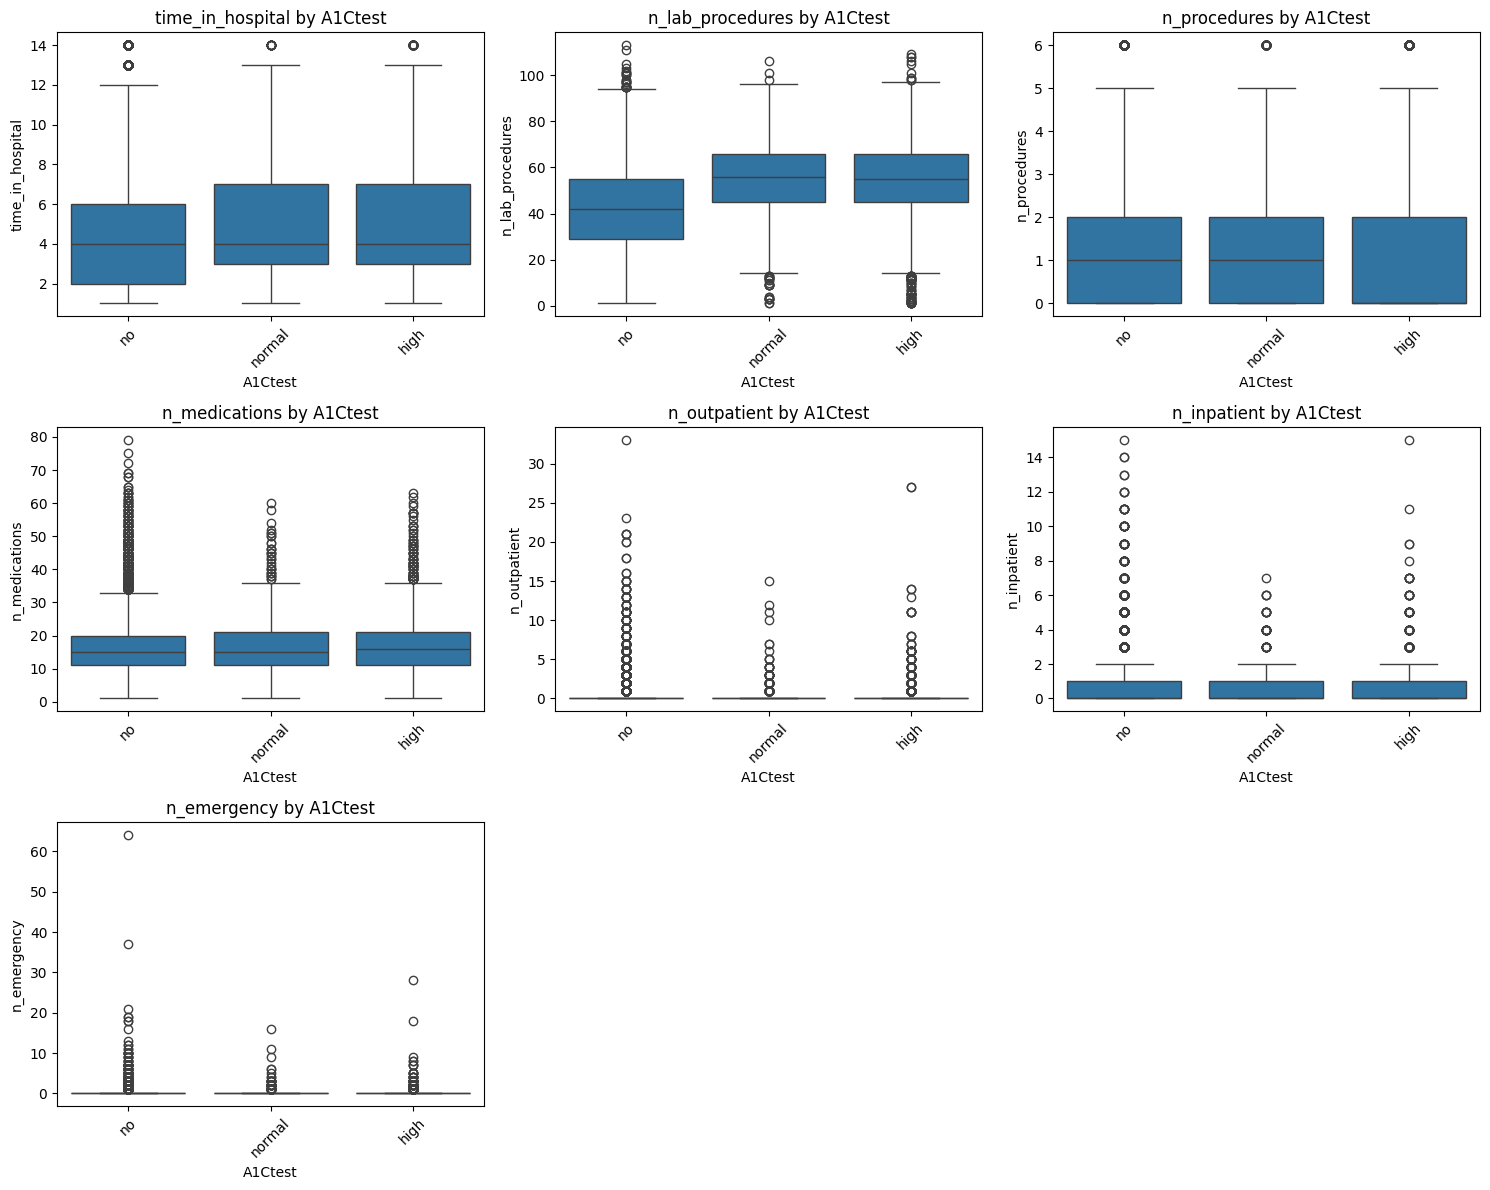

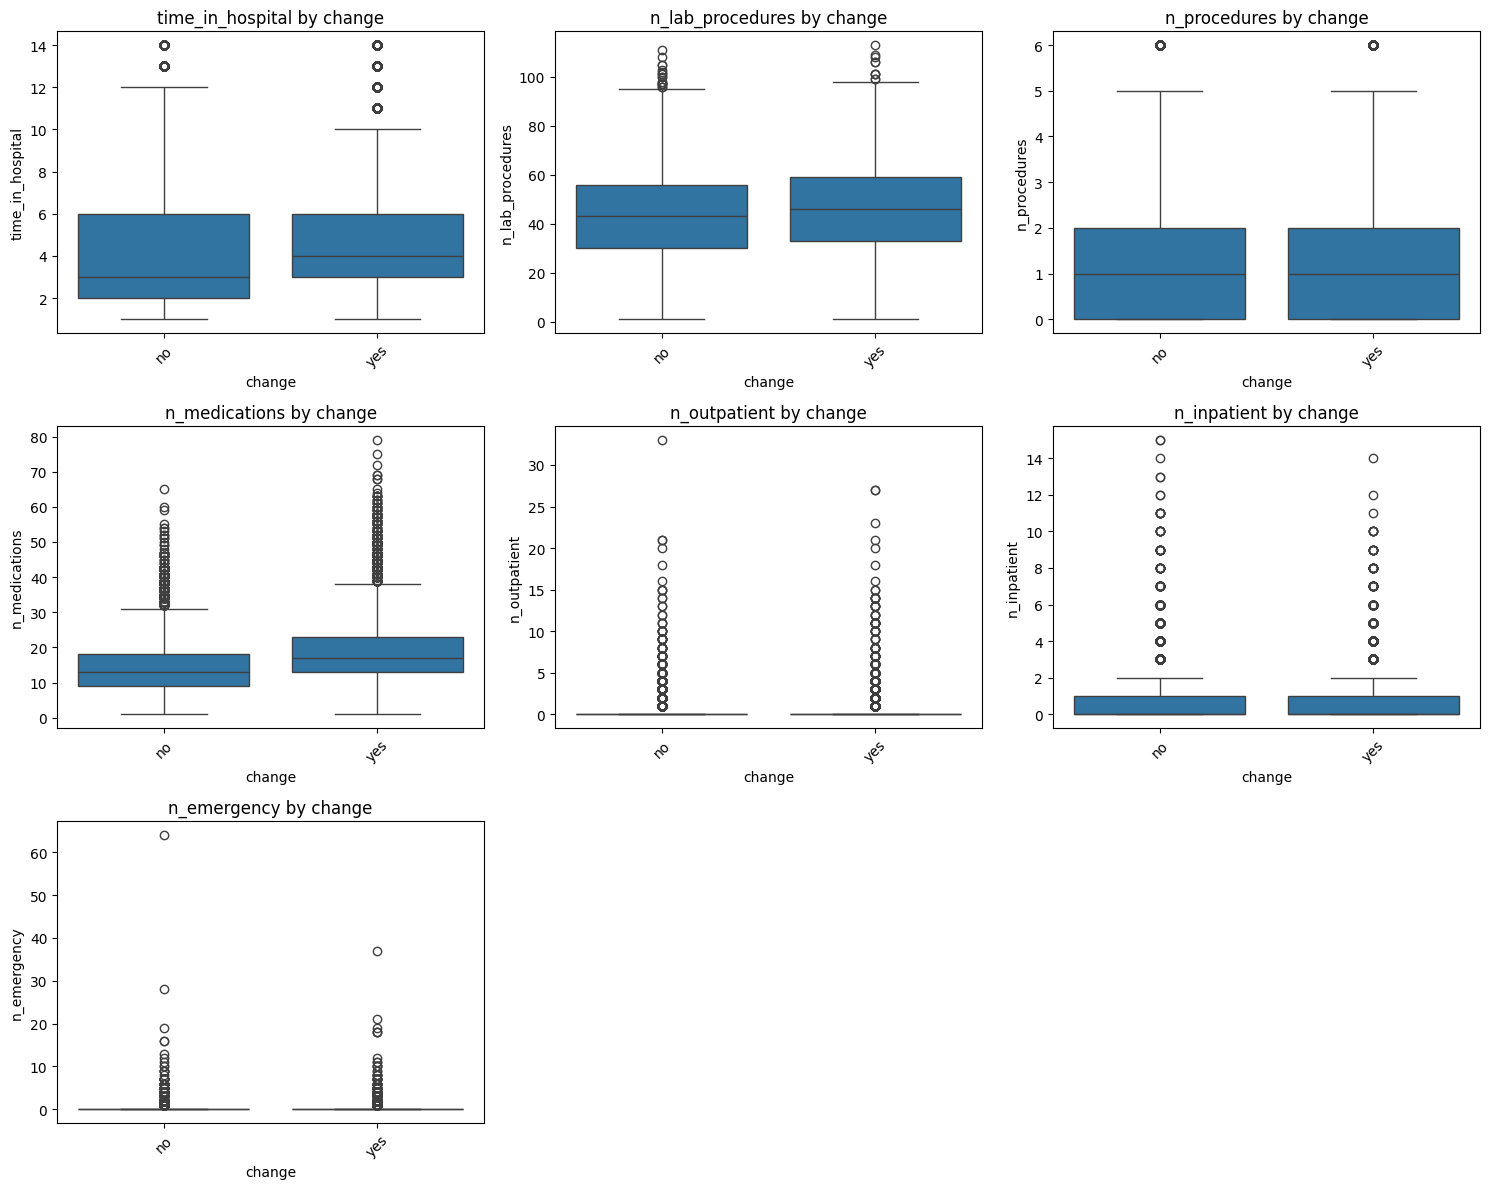

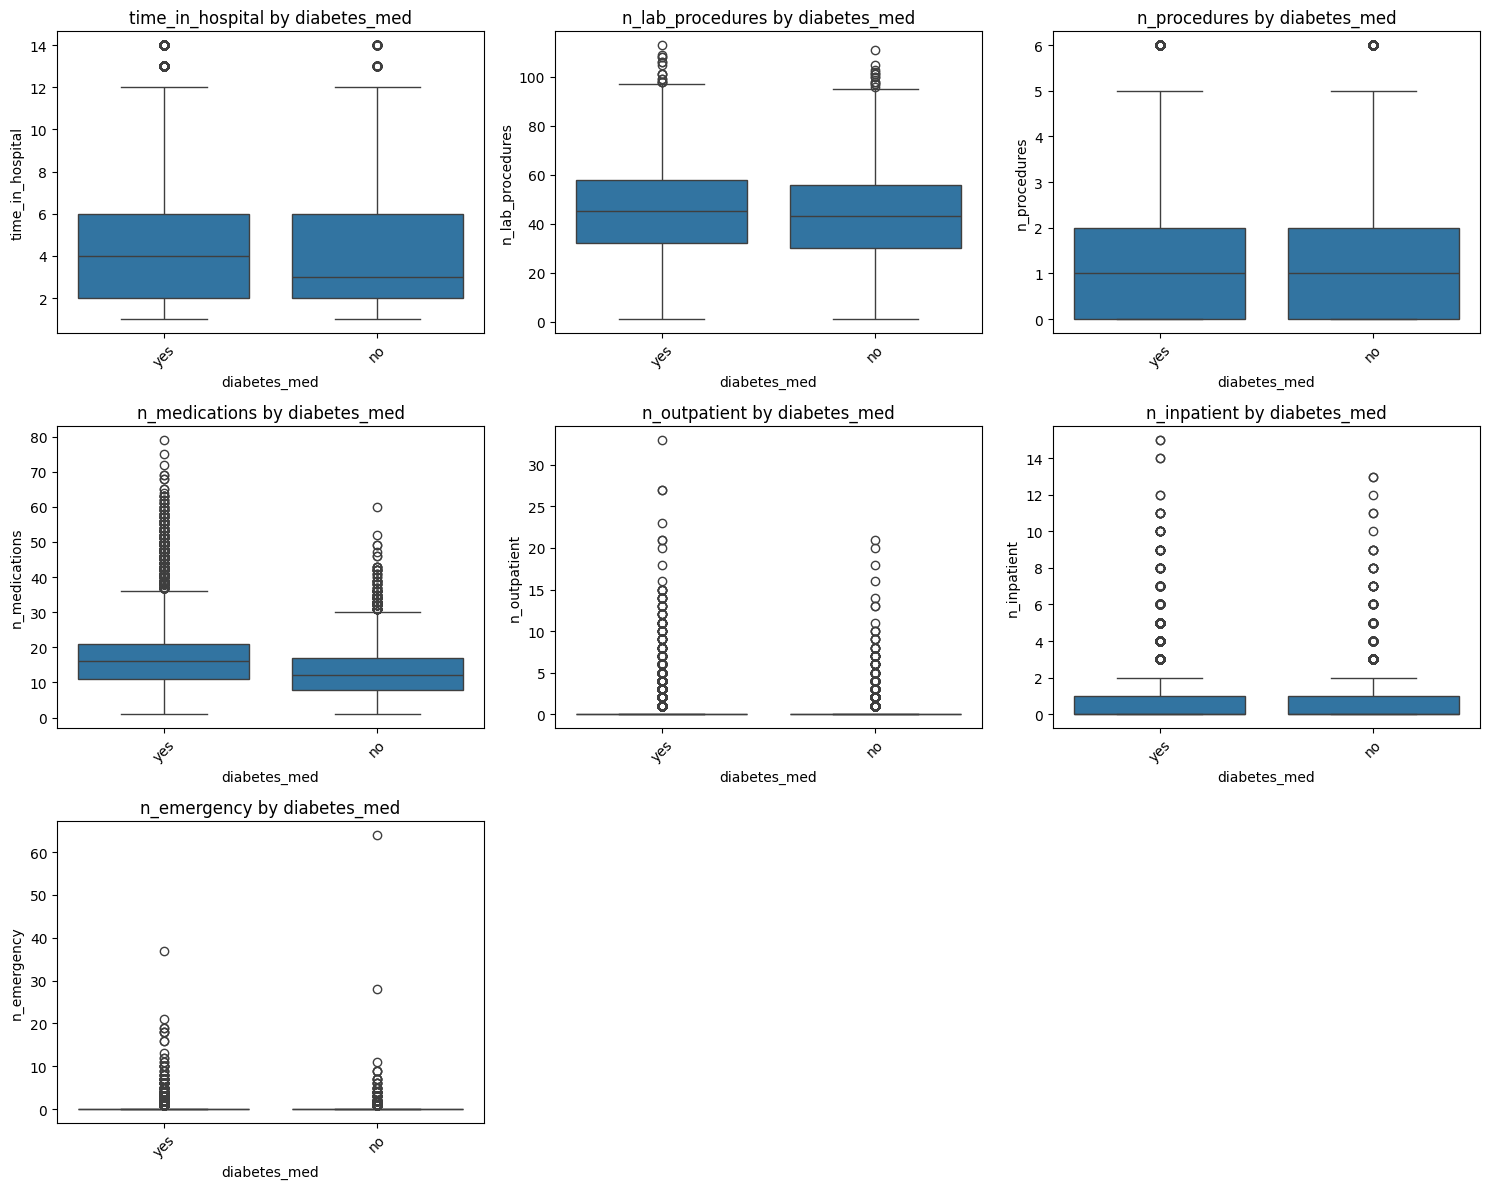

In [11]:
for t_feature in categorical_features:
    n_numerical_features = len(numerical_features)
    ncols = 3
    nrows = (n_numerical_features + ncols - 1) // ncols

    g, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))


    if n_numerical_features > 1:
        axes_flat = axes.flatten()
    else:
        axes_flat = [axes]

    for i, num_feature in enumerate(numerical_features):
        ax = axes_flat[i]
        sns.boxplot(
            x=dataset[t_feature],
            y=dataset[num_feature],
            ax=ax
        )
        ax.set_title(f'{num_feature} by {t_feature}')
        ax.set_xlabel(t_feature)
        ax.set_ylabel(num_feature)
        ax.tick_params(axis='x', rotation=45)

    # Hide any unused subplots
    for j in range(i + 1, len(axes_flat)):
        axes_flat[j].set_visible(False)

    plt.tight_layout()
    plt.show()

In the previous plots we can see how the distribution of the numerical features changes across the different categories of the categorical features. For example, we can see that patients with more than 80 years old tend to have more medications and more lab procedures than younger patients. We can also see that patients with more than 80 years old tend to stay more days in hospital. We can also see that patients with more than 80 years old tend to be readmitted more often than younger patients. That is why we notice that there are a several overlays between different variables.

,n_lab_procedures,n_procedures,n_medications,n_outpatient,n_inpatient,n_emergency
readmitted,,,,,,
no,42.625245,1.424204,15.972445,0.258871,0.380190,0.108561
yes,43.934405,1.271397,16.567892,0.487579,0.881657,0.274545


<Figure size 400x300 with 0 Axes>

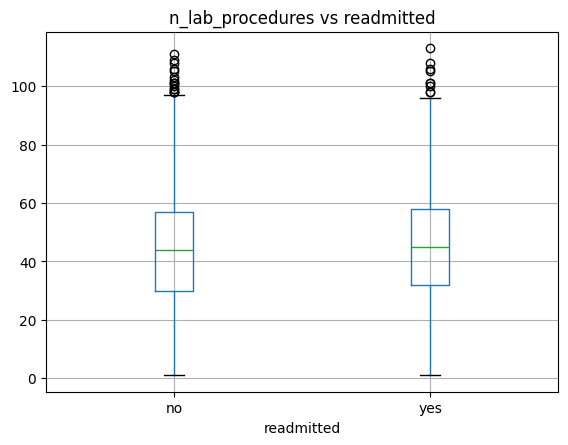

<Figure size 400x300 with 0 Axes>

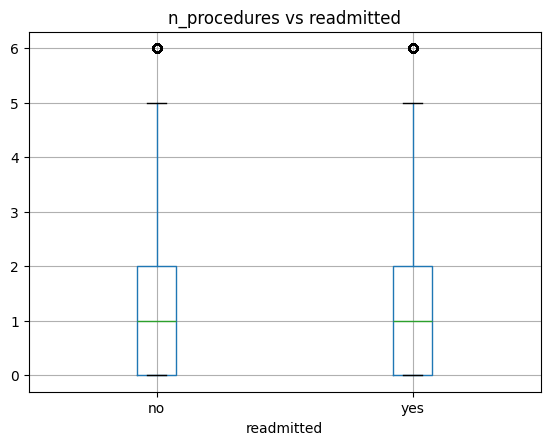

<Figure size 400x300 with 0 Axes>

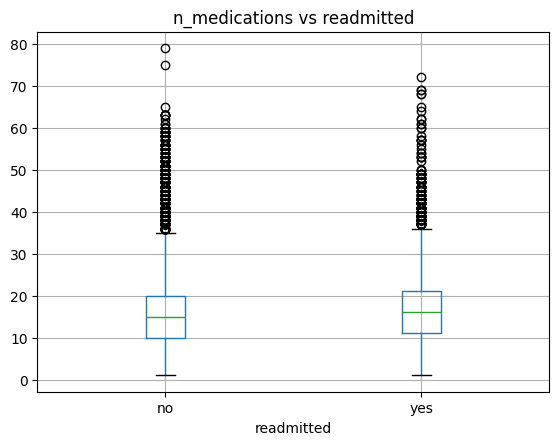

<Figure size 400x300 with 0 Axes>

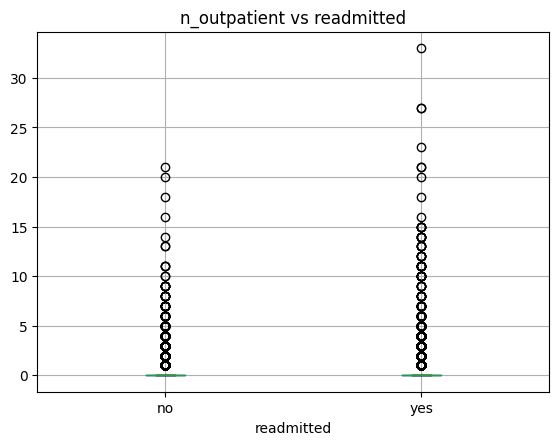

<Figure size 400x300 with 0 Axes>

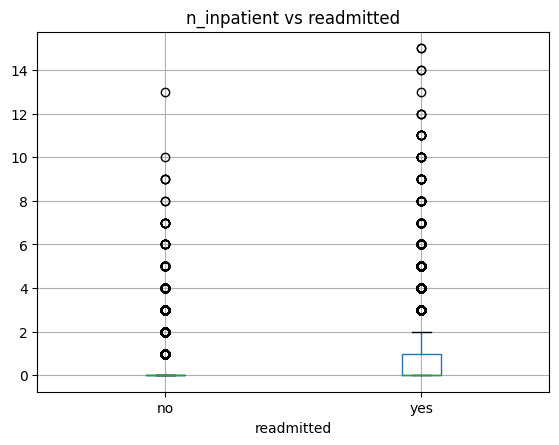

<Figure size 400x300 with 0 Axes>

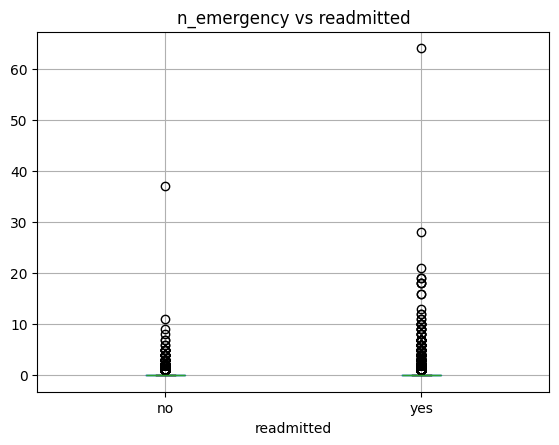

In [13]:
# Relationship between readmitted and numerical features

# We compute the mean of the numerical features
display(dataset.groupby('readmitted')[count_features].mean())

# Boxplots
for c in count_features:
    plt.figure(figsize=(4,3))
    dataset.boxplot(column=c, by='readmitted')
    plt.title(f"{c} vs readmitted")
    plt.suptitle("")
    plt.show()
    

As we saw previously, the difference between readmitted and non-readmitted patients was fairly balanced. In these boxplots, we compare the numerical features between readmitted and non-readmitted patients. We observe that the mean between the distributions is slightly higher for readmitted patients.

In [14]:
def readmit_rate(col):
    tab = pd.crosstab(dataset[col], dataset['readmitted'], normalize='index')
    return tab.sort_values('yes', ascending=False)

for col in ['age','glucose_test','A1Ctest','diabetes_med','change','medical_specialty']:
    print("\n", col)
    display(readmit_rate(col).head(15))


 age


readmitted,no,yes
age,,
[80-90),0.504207,0.495793
[70-80),0.512067,0.487933
[60-70),0.531541,0.468459
[40-50),0.554897,0.445103
[50-60),0.558401,0.441599
[90-100),0.578667,0.421333



 glucose_test


readmitted,no,yes
glucose_test,,
high,0.479592,0.520408
normal,0.516691,0.483309
no,0.531683,0.468317



 A1Ctest


readmitted,no,yes
A1Ctest,,
no,0.525504,0.474496
high,0.540502,0.459498
normal,0.578947,0.421053


... (2 outputs left out)


 change


readmitted,no,yes
change,,
yes,0.506477,0.493523
no,0.549752,0.450248



 medical_specialty


readmitted,no,yes
medical_specialty,,
Family/GeneralPractice,0.504782,0.495218
Emergency/Trauma,0.506101,0.493899
Missing,0.510903,0.489097
Cardiology,0.550035,0.449965
InternalMedicine,0.552314,0.447686
Other,0.585210,0.414790
Surgery,0.587799,0.412201


Conversely, if we compare readmitted patients with categorical variables, we see that categorical variables alone do not significantly differentiate readmitted patients from non-readmitted patients (both are around 40-58%). This suggests that these variables have little discriminatory power to predict readmission.

Next, once we have performed the exploratory data analysis on the entire dataset, we will try to justify which columns we should not use as inputs. The main idea is to predict a patient's admission; therefore, we cannot use features that depend on what happened during the admission.

In [15]:
# We write down the features that can introduce data leakage
leakage_ft = ['n_lab_procedures', 'n_procedures', 'n_medications',
    'glucose_test', 'A1Ctest', 'change', 'diabetes_med']
print("Posibles leakage features:", leakage_ft)


Posibles leakage features: ['n_lab_procedures', 'n_procedures', 'n_medications', 'glucose_test', 'A1Ctest', 'change', 'diabetes_med']


Variables such as glucose tests, A1C tests, changes in diabetes medication, and receipt of diabetes medication are features that reflect clinical decisions made during a patient's admission. Additionally, lab procedures, the number of procedures, and medication are actions performed during that admission. If we make a prediction without removing these variables, we will experience data leakage.

In [16]:
# Finally, we select the final features to avoid data leakage and separate the dataset
# into classification and regression to achieve the lab goals.

selected_features = [
    'age',
    'medical_specialty',
    'diag_1', 'diag_2', 'diag_3',
    'n_outpatient', 'n_inpatient', 'n_emergency'
]

# Dataset for classification -- predict readmission
X_class = dataset[selected_features].copy()
y_class = dataset['readmitted'].copy()

# Dataset for regression -- predict length of stay
X_reg = dataset[selected_features].copy()
y_reg = dataset['time_in_hospital'].copy()

print("Classification:", X_class.shape, y_class.shape)
print("Regression:", X_reg.shape, y_reg.shape)

Classification: (25000, 8) (25000,)
Regression: (25000, 8) (25000,)


In this exploratory data analysis, we observed that the readmitted variable shows a fairly balanced distribution between patients who are readmitted and those who are not, thus eliminating the need for aggressive balancing techniques. On the other hand, the length of hospital stay variable is skewed towards short stays, with the exception of some patients with longer stays. This may be directly influenced by clinical factors and the patient's medical history.

Regarding the analysis of the numerical count variables, we observed that both histograms and boxplots show some asymmetry with many low and zero values, as well as numerous outliers, especially in outpatient, inpatient, and emergency departments. When we examined the relationships between these numerical variables, we found no strong correlations between most of the counts, but there was a slight positive trend between lab procedures and medication.

When we compare readmitted patients with categorical features (age, glucose test, medical specialty), we observe that the proportions between non-readmitted and readmitted patients are very similar, and in most cases, the proportion of non-readmitted patients is slightly higher. This suggests that these categorical variables have little discriminatory power to separate these types of patients, but that they could provide information when combined with other variables.

Finally, to achieve the objective of predicting readmitted patients and length of stay, we must avoid data leakage. Therefore, we propose eliminating variables that depend on admission (tests, medication) and selecting the final set that is independent of this: age, medical specialty, diagnosis 1, diagnosis 2, diagnosis 3, number of outpatients, number of inpatients, number of emergency patients. It is with this set that we construct the datasets for classification (readmitted patients) and regression (time in hospital) without data leakage.

Hypothesis: Older age, types of diagnosis, and number of outpatient/inpatient/emergency patients should be associated with a higher readmission rate as well as longer stays, since both act as proxies for disease severity and chronic complexity.


### **2. Preprocessing pipeline**



In [17]:
from sklearn.model_selection import train_test_split

In [18]:
selected_features = [
    'age',
    'medical_specialty',
    'diag_1', 'diag_2', 'diag_3',
    'n_outpatient', 'n_inpatient', 'n_emergency'
]

# For CLASSIFICATION
X_class = dataset[selected_features].copy()
y_class = dataset['readmitted'].copy()

# For REGRESSION
X_reg = dataset[selected_features].copy()
y_reg = dataset['time_in_hospital'].copy()

# We split the data
X_class_train, X_class_test, y_class_train, y_class_test = train_test_split(X_class, y_class.squeeze(), test_size = 0.2, random_state = 42, stratify = y_class)
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(X_reg, y_reg.squeeze(), test_size = 0.2, random_state = 42)

print('Classification train/test: ', X_class_train.shape, X_class_test.shape)
print('Regression train/test: ', X_reg_train.shape, X_reg_test.shape)

Classification train/test:  (20000, 8) (5000, 8)
Regression train/test:  (20000, 8) (5000, 8)


In [19]:
# Preprocessing pipeline
# We import the modules seen in class
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    OrdinalEncoder
)
from sklearn.impute import SimpleImputer

In [20]:
# Once we have our dataset divided into train and test, we should define which
# columns are numerical and which are categorical from the selected features:

count_ft = ['n_outpatient', 'n_inpatient', 'n_emergency']
ordinal_ft = ['age']
nominal_ft = ['medical_specialty', 'diag_1', 'diag_2', 'diag_3']

# Correct order for age
age_order = ['[0-10)', '[10-20)', '[20-30)', '[30-40)', '[40-50)',
             '[50-60)', '[60-70)', '[70-80)', '[80-90)', '[90-100)']

# We define the pipelines for type
count_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
ordinal_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(categories=[age_order])),
    ('scaler', StandardScaler())
])
nominal_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(sparse_output=False, handle_unknown='ignore'))
])

# We define the preprocessor

preprocessor = ColumnTransformer(transformers=[
    ('count', count_transformer, count_ft),
    ('ordinal', ordinal_transformer, ordinal_ft),
    ('nominal', nominal_transformer, nominal_ft)
],
remainder = 'drop'
)

In [21]:
# Check the preprocessor output for the classification dataset

X_class_train_preprocessed = preprocessor.fit_transform(X_class_train)
X_class_test_preprocessed = preprocessor.transform(X_class_test)

print('X class train preprocessed shape: ', X_class_train_preprocessed.shape)
print('X class test preprocessed shape: ', X_class_test_preprocessed.shape)

X class train preprocessed shape:  (20000, 35)
X class test preprocessed shape:  (5000, 35)


In [22]:
feature_names = preprocessor.get_feature_names_out()
len(feature_names), feature_names[:]

(35,
 array(['count__n_outpatient', 'count__n_inpatient', 'count__n_emergency',
        'ordinal__age', 'nominal__medical_specialty_Cardiology',
        'nominal__medical_specialty_Emergency/Trauma',
        'nominal__medical_specialty_Family/GeneralPractice',
        'nominal__medical_specialty_InternalMedicine',
        'nominal__medical_specialty_Missing',
        'nominal__medical_specialty_Other',
        'nominal__medical_specialty_Surgery',
        'nominal__diag_1_Circulatory', 'nominal__diag_1_Diabetes',
        'nominal__diag_1_Digestive', 'nominal__diag_1_Injury',
        'nominal__diag_1_Missing', 'nominal__diag_1_Musculoskeletal',
        'nominal__diag_1_Other', 'nominal__diag_1_Respiratory',
        'nominal__diag_2_Circulatory', 'nominal__diag_2_Diabetes',
        'nominal__diag_2_Digestive', 'nominal__diag_2_Injury',
        'nominal__diag_2_Missing', 'nominal__diag_2_Musculoskeletal',
        'nominal__diag_2_Other', 'nominal__diag_2_Respiratory',
        'nominal__di

We observe that we have gone from having 8 features to 31. If we print the name of each one, we will see that the first 4 columns correctly correspond to the features for outpatient, inpatient, emergency, and age. From this, we obtain new columns from the OneHotEncoder corresponding to each medical specialty and for the different types of diagnoses.

For the OneHotEncoder, we add `drop='first'` to the class, which removes one column for each categorical variable. This way, instead of having k columns for k categories, we have k-1 columns. This is useful for avoiding multicollinearity, where the missing category is the reference category, so when the other columns are 0, it means we have the base category.

For this second task, we implemented the preprocessing pipeline discussed in class, using ColumnTransformer to apply different transformations depending on the feature type. We began by separating the selected variables into count, ordinal, and nominal.

For the count group, we imputed (learn the median) and standardized. For the ordinal age feature, we imputed and encoded, following the logical age order established before scaling. For the nominal features, we imputed and one-hot encoded.

The preprocessing is only applied to the training set and then to the test set to avoid data leakage, as otherwise we would be using information from the test to learn from the data. Since we have two goals (classification and regression), we apply the same preprocessing to both.

### **3. Key evaluation metric**

In this lab, we have two tasks: one for classification and one for regression. Therefore, we will use two different evaluation metrics.

For the classification task, in which we must predict readmitted patients, we will use the F1 score. Although we have a mostly balanced dataset, when dealing with health data, it is always important to balance precision and recall. In our case, we don't want to miss too many false negatives (patients who are readmitted), but we also don't want to generate too many false positives. For this reason, the F1 score is a robust metric that allows us to combine both and evaluate overall performance.

Regarding the regression task, we want to predict a patient's length of stay. We know that this variable is biased towards short stays with some extreme values. Consequently, we decided to use the Mean Absolute Error (MAE) metric. This metric allows measuring the average error in days and is less sensitive to outliers, therefore, it cannot provide a more stable assessment of the model's typical error.

### **4. k-fold cross-validation pipeline**

We will apply this pipeline for each of the following algorithms:

• Linear regression.

• Logistic regression.

• k-NN.

• Decision Tree.

• Random forest.

• Gradient boosting machine.

• Support vector machine.

• Neural network.


For the two tasks in this lab, we have several models that we must fairly compare to choose the best fit. To do this, we use cross-validation (CV) with a k-fold of 5. Therefore, we train the model 5 times, using 4 folds for training and 1 fold for validation.

For each algorithm in the list, we investigate two hyperparameters using GridSearchCV, where we test all defined combinations and select the one that gives us the best average performance. Furthermore, to avoid data leakage, we include all preprocessing within a pipeline.

We perform the experiments for both tasks using the previously established metrics: F1 score and MAE.

In [23]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold, KFold
from sklearn.pipeline import Pipeline

In [24]:
cv_class = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_reg   = KFold(n_splits=5, shuffle=True, random_state=42)

metric_class = "f1"
metric_reg   = "neg_mean_absolute_error"

In [25]:
y_class_train_bin = y_class_train.map({'no': 0, 'yes': 1}) if y_class_train.dtype == "object" else y_class_train
y_class_test_bin  = y_class_test.map({'no': 0, 'yes': 1})  if y_class_test.dtype == "object" else y_class_test

print(y_class_train_bin.value_counts())

readmitted
no     10597
yes     9403
Name: count, dtype: int64


In [26]:
# We import the models from the list
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.svm import SVC, SVR
from sklearn.neural_network import MLPClassifier, MLPRegressor

In [27]:
def run_gridsearch(model, param_grid, X_train, y_train, cv, scoring):
    # we create a pipeline that includes the preprocess and model
    pipe = Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", model)
    ])

    # we execute GridSearch with k-fold cross-validation
    gs = GridSearchCV(
        estimator=pipe, # Changed from 'model' to 'pipe'
        param_grid=param_grid,
        n_jobs=-1,
        cv=cv,
        scoring=scoring
    )

    gs.fit(X_train, y_train)
    return gs

In [28]:
# We use a function that normalizes text by lowercasing and stripping whitespace before mapping
print("Unique values in y_class_train before mapping:", y_class_train.unique())
def clean_and_map(val):
    val_str = str(val).lower().strip()
    if val_str in ['no', '0']: 
        return 0
    elif val_str in ['yes', '1', '<30', '>30']: # We assume that all "yes" and "1" values are positive cases, and we also include the "<30" and ">30" as positive cases since they indicate readmission within 30 days or after 30 days, which are both relevant for the readmission prediction task.
        return 1
    return np.nan

y_class_train_bin = y_class_train.apply(clean_and_map)
y_class_test_bin = y_class_test.apply(clean_and_map)

# Check the results of the mapping
nan_count = y_class_train_bin.isnull().sum()
print(f"NaNs found in y_train after mapping: {nan_count}")

if nan_count > 0:
    print("There are still unmapped values. These rows will be removed.")
    # Erase rows with NaN in the target (only if there are still unmapped values)
    valid_indices = ~y_class_train_bin.isnull()
    X_class_train = X_class_train[valid_indices]
    y_class_train_bin = y_class_train_bin[valid_indices].astype(int)

print("Unique values in y_class_train_bin:", y_class_train_bin.unique())

Unique values in y_class_train before mapping: <StringArray>
['no', 'yes']
Length: 2, dtype: str
NaNs found in y_train after mapping: 0
Unique values in y_class_train_bin: [0 1]


In [29]:
# CLASSIFICATION (readmitted)
# Logistic Regression, kNN, Decision Tree, Random Forest, GMB, SVM, MLP
models_class = {
    "LogisticRegression": (
        LogisticRegression(max_iter=5000, solver='liblinear'),
        {"model__C": [0.1, 1, 10],
         "model__penalty": ["l1", "l2"]}
    ),
    "kNN": (
        KNeighborsClassifier(),
        {"model__n_neighbors": [15, 25, 35],
         "model__weights": ["uniform", "distance"]}
    ),
    "DecisionTree": (
        DecisionTreeClassifier(random_state=42),
        {"model__max_depth": [5, 10, 15],
         "model__min_samples_split": [5, 20]}
    ),
    "RandomForest": (
        RandomForestClassifier(random_state=42, n_jobs=-1),
        {"model__n_estimators": [100, 300],
         "model__max_depth": [10, 20]}
    ),
    "GradientBoosting": (
        GradientBoostingClassifier(random_state=42),
        {"model__n_estimators": [100, 300],
         "model__learning_rate": [0.05, 0.1]}
    ),
    "SVM": (
        SVC(kernel='rbf'),
        {"model__C": [0.5, 1, 5],
         "model__kernel": ["scale", "auto"]}
    ),
    "NeuralNetwork": (
        MLPClassifier(max_iter=2000, random_state=42),
        {"model__hidden_layer_sizes": [(50,), (100,), (50, 50)],
         "model__alpha": [0.001, 0.01]}
    ),
}

In [30]:
# We execute the GridSearchCV with 5-fold
# Since we are doing the readmitted task we compute the F1 score
results_class = []

# Correct the SVM model parameters for the current execution
# The original error was due to 'model__kernel': ["scale", "auto"]
# 'scale' and 'auto' are valid for gamma, not kernel.
# Valid kernels are 'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'.
# Overriding the SVM entry in models_class for this cell's execution.
models_class["SVM"] = (
    SVC(kernel='rbf', probability=True, random_state=42), # Added random_state for consistency and probability=True for f1-scoring
    {"model__C": [0.5, 1, 5],
     "model__kernel": ["linear", "rbf"]} # Use valid kernel options
)


for name, (model, grid) in models_class.items():
    print(f"Running CLASSIFICATION: {name}")

    gs = run_gridsearch(
        model=model,
        param_grid=grid,
        X_train=X_class_train,
        y_train=y_class_train_bin,
        cv=cv_class,
        scoring=metric_class
    )

    results_class.append({
        "model": name,
        "best_f1_cv": gs.best_score_,
        "best_params": gs.best_params_
    })

df_class = pd.DataFrame(results_class).sort_values("best_f1_cv", ascending=False)
df_class

Running CLASSIFICATION: LogisticRegression


c:\Proyectos\ML\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Proyectos\ML\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Running CLASSIFICATION: kNN
Running CLASSIFICATION: DecisionTree
Running CLASSIFICATION: RandomForest
Running CLASSIFICATION: GradientBoosting
Running CLASSIFICATION: SVM


KeyboardInterrupt: 

In [ ]:
models_reg = {
    "LinearRegression": (
        LinearRegression(),
        {"model__fit_intercept": [True, False],
         "model__positive": [True, False]}
    ),
    "kNN": (
        KNeighborsRegressor(),
        {"model__n_neighbors": [3, 7, 15],
         "model__weights": ["uniform", "distance"]}
    ),
    "DecisionTree": (
        DecisionTreeRegressor(random_state=42),
        {"model__max_depth": [None, 5, 10],
         "model__min_samples_split": [2, 10, 30]}
    ),
    "RandomForest": (
        RandomForestRegressor(random_state=42, n_jobs=-1),
        {"model__n_estimators": [100, 300],
         "model__max_depth": [None, 10, 20]}
    ),
    "GradientBoosting": (
        GradientBoostingRegressor(random_state=42),
        {"model__n_estimators": [100, 300],
         "model__learning_rate": [0.05, 0.1]}
    ),
    "SVM": (
        SVR(),
        {"model__C": [0.5, 1, 5],
         "model__kernel": ["linear", "rbf"]}
    ),
    "NeuralNetwork": (
        MLPRegressor(max_iter=2000, random_state=42),
        {"model__hidden_layer_sizes": [(50,), (100,)],
         "model__alpha": [1e-4, 1e-3]}
    ),
}

In [ ]:
results_reg = []

for name, (model, grid) in models_reg.items():
    print(f"Running REGRESSION: {name}")

    gs = run_gridsearch(
        model=model,
        param_grid=grid,
        X_train=X_reg_train,
        y_train=y_reg_train,
        cv=cv_reg,
        scoring=metric_reg
    )

    results_reg.append({
        "model": name,
        "best_MAE_cv": -gs.best_score_,  # neg_mean_absolute_error -> MAE positivo
        "best_params": gs.best_params_
    })

df_reg = pd.DataFrame(results_reg).sort_values("best_MAE_cv", ascending=True)
df_reg

Running REGRESSION: LinearRegression
Running REGRESSION: kNN
Running REGRESSION: DecisionTree
Running REGRESSION: RandomForest
Running REGRESSION: GradientBoosting
Running REGRESSION: SVM
Running REGRESSION: NeuralNetwork


,model,best_MAE_cv,best_params
5,SVM,2.208402,"{'model__C': 0.5, 'model__kernel': 'rbf'}"
4,GradientBoosting,2.280741,"{'model__learning_rate': 0.05, 'model__n_estim..."
3,RandomForest,2.291353,"{'model__max_depth': 10, 'model__n_estimators'..."
0,LinearRegression,2.293616,"{'model__fit_intercept': False, 'model__positi..."
2,DecisionTree,2.317984,"{'model__max_depth': 5, 'model__min_samples_sp..."
6,NeuralNetwork,2.319447,"{'model__alpha': 0.001, 'model__hidden_layer_s..."
1,kNN,2.344383,"{'model__n_neighbors': 15, 'model__weights': '..."


### **5. Define your baselines, compute test metrics, and select your best model per task**

--- CLASSIFICATION ASSESSMENT (Target: Readmitted) ---

Baseline F1 Score (Most Frequent): 0.0000

Best Model identified by CV: RandomForest
Best CV F1 Score: 0.5368
Test Set F1 Score: 0.5328
Improvement over Baseline: 0.5328

Classification Report:

              precision    recall  f1-score   support

           0       0.61      0.73      0.66      2649
           1       0.61      0.47      0.53      2351

    accuracy                           0.61      5000
   macro avg       0.61      0.60      0.60      5000
weighted avg       0.61      0.61      0.60      5000

Confusion Matrix:


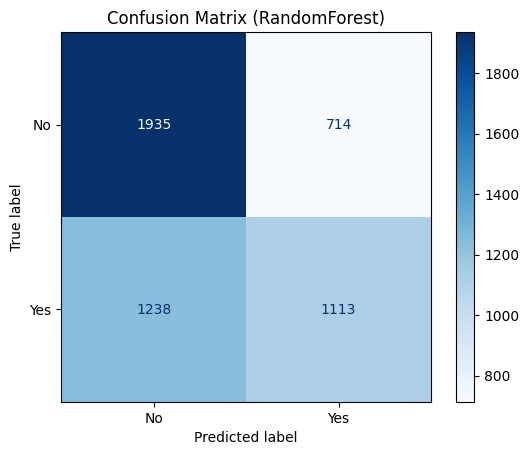

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

print("--- CLASSIFICATION ASSESSMENT (Target: Readmission) ---\n")

# BASELINE (The "Dumb" Model)
# We use 'most_frequent' strategy: always predict the majority class (No Readmission)
dummy_clf = DummyClassifier(strategy="most_frequent")
dummy_clf.fit(X_class_train, y_class_train_bin)
y_pred_dummy = dummy_clf.predict(X_class_test)
baseline_f1 = f1_score(y_class_test_bin, y_pred_dummy)

print(f"Baseline F1 Score (Most Frequent): {baseline_f1:.4f}")

# RETRIEVE BEST MODEL FROM GRID SEARCH
# We take the top row from df_class dataframe
best_model_name = df_class.iloc[0]['model']
best_params = df_class.iloc[0]['best_params']
best_cv_score = df_class.iloc[0]['best_f1_cv']

print(f"\nBest Model identified by CV: {best_model_name}")
print(f"Best CV F1 Score: {best_cv_score:.4f}")

# RE-TRAIN AND EVALUATE ON TEST SET
# We reconstruct the pipeline using the base model from the dictionary and the best params
best_base_model = models_class[best_model_name][0]

best_pipe_class = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", best_base_model)
])

# Set the best parameters found 
best_pipe_class.set_params(**best_params)

# Fit on the full training data
best_pipe_class.fit(X_class_train, y_class_train_bin)

# Predict on the test data (Final Evaluation)
y_pred_class = best_pipe_class.predict(X_class_test)
final_f1 = f1_score(y_class_test_bin, y_pred_class)

print(f"Test Set F1 Score: {final_f1:.4f}")
print(f"Improvement over Baseline: {final_f1 - baseline_f1:.4f}")

# Visualizing the results
print("\nClassification Report:\n")
print(classification_report(y_class_test_bin, y_pred_class))

# Confusion Matrix
print("Confusion Matrix:")
cm = confusion_matrix(y_class_test_bin, y_pred_class)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No', 'Yes'])
disp.plot(cmap='Blues')
plt.title(f"Confusion Matrix ({best_model_name})")
plt.show()


--- REGRESSION ASSESSMENT (Target: Time in Hospital) ---

Baseline MAE (Mean Prediction): 2.3786 days

Best Model identified by CV: SVM
Best CV MAE: 2.2084 days
Test Set MAE: 2.1942 days
Improvement over Baseline: 0.1844 days


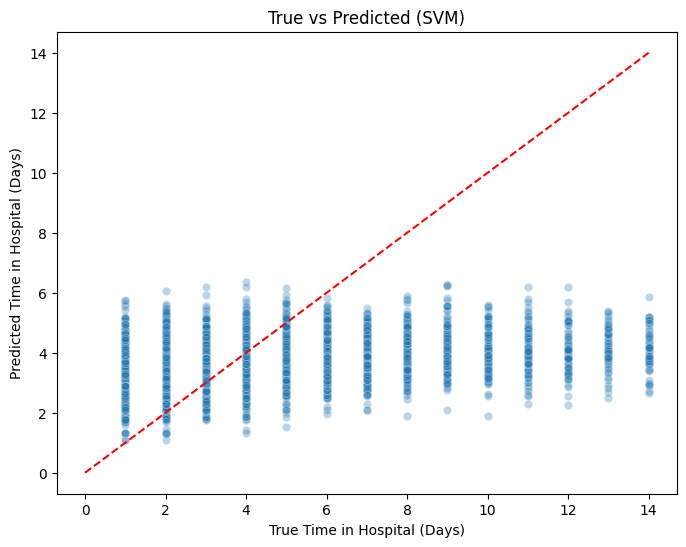

In [ ]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("\n--- REGRESSION ASSESSMENT (Target: Time in Hospital) ---\n")

# BASELINE (The "Dumb" Model)
# We use 'mean' strategy: always predict the average hospital stay
dummy_reg = DummyRegressor(strategy="mean")
dummy_reg.fit(X_reg_train, y_reg_train)
y_pred_dummy_reg = dummy_reg.predict(X_reg_test)
baseline_mae = mean_absolute_error(y_reg_test, y_pred_dummy_reg)

print(f"Baseline MAE (Mean Prediction): {baseline_mae:.4f} days")

# RETRIEVE BEST MODEL FROM GRID SEARCH
best_reg_name = df_reg.iloc[0]['model']
best_reg_params = df_reg.iloc[0]['best_params']
best_cv_mae = df_reg.iloc[0]['best_MAE_cv']

print(f"\nBest Model identified by CV: {best_reg_name}")
print(f"Best CV MAE: {best_cv_mae:.4f} days")

# RE-TRAIN AND EVALUATE ON TEST SET
best_base_reg = models_reg[best_reg_name][0]

best_pipe_reg = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", best_base_reg)
])

# Set the best parameters
best_pipe_reg.set_params(**best_reg_params)

# Fit on training data
best_pipe_reg.fit(X_reg_train, y_reg_train)

# Predict on test data
y_pred_reg = best_pipe_reg.predict(X_reg_test)
final_mae = mean_absolute_error(y_reg_test, y_pred_reg)

print(f"Test Set MAE: {final_mae:.4f} days")
print(f"Improvement over Baseline: {baseline_mae - final_mae:.4f} days")

# Visualization: True vs Predicted
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_reg_test, y=y_pred_reg, alpha=0.3)
plt.plot([0, 14], [0, 14], color='red', linestyle='--') # Identity line
plt.xlabel("True Time in Hospital (Days)")
plt.ylabel("Predicted Time in Hospital (Days)")
plt.title(f"True vs Predicted ({best_reg_name})")
plt.show()

**Baselines:** We use DummyClassifier (predicting the majority class) and DummyRegressor (predicting the mean) to establish a "floor." If the best complex model (like Gradient Boosting) cannot beat these numbers significantly, the model is not useful.

**Final Metric:** The "Test Set" metric represents how the model handles completely new patients.

In [ ]:
from sklearn.metrics import matthews_corrcoef, roc_auc_score, mean_squared_error, r2_score

# --- CLASSIFICATION MISSING METRICS (Best Model: Random Forest) ---
y_pred_class = best_pipe_class.predict(X_class_test)
y_prob_class = best_pipe_class.predict_proba(X_class_test)[:, 1]

roc_auc = roc_auc_score(y_class_test_bin, y_prob_class)
mcc = matthews_corrcoef(y_class_test_bin, y_pred_class)

print(f"--- Missing Classification Metrics ---")
print(f"ROC-AUC: {roc_auc:.4f}")
print(f"MCC: {mcc:.4f}")

# --- REGRESSION MISSING METRICS (Best Model: SVM) ---
y_pred_reg = best_pipe_reg.predict(X_reg_test)

mse = mean_squared_error(y_reg_test, y_pred_reg)
rmse = np.sqrt(mse)
r2 = r2_score(y_reg_test, y_pred_reg)

print(f"\n--- Missing Regression Metrics ---")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2 Score: {r2:.4f}")

--- Missing Classification Metrics ---
ROC-AUC: 0.6448
MCC: 0.2113

--- Missing Regression Metrics ---
MSE: 9.0117
RMSE: 3.0020
R2 Score: 0.0071
